# ML4N – Project 8: investigation and cleaning of the DDoS dataset

This notebook is the first section of the project. It explores the dataset of network flows, finds the columns that are useless, redundant, identifying or corrupted, and ends with the cleaned dataset used by the following sections. No model is trained here.

## 1. Introduction

**The dataset.** Each row is a network *flow*: the packets exchanged between a source and a destination (IP address and port) with a given transport protocol. The flows come from the CIC-DDoS2019 dataset and were extracted with CICFlowMeter, which summarises each flow with about 80 statistics: duration, number and size of the packets in each direction, inter-arrival times, TCP flags, byte and packet rates, and so on. Each row also carries the identifiers of the flow (Flow ID, IP addresses, ports, protocol, timestamp) and its ground-truth label.

**The classes.** The column `label` takes 12 values: `benign`, the normal traffic, and 11 DDoS attacks. Eight are reflection/amplification attacks named after the service they abuse (`ddos_dns`, `ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_ntp`, `ddos_snmp`, `ddos_ssdp`, `ddos_tftp`); the other three are floods (`ddos_syn`, TCP SYN flood; `ddos_udp` and `ddos_udp_lag`, UDP floods).

**Goal.** Before training a classifier we need to know what the data look like and which columns can be trusted. The notebook answers four questions:

1. how the file is structured and whether it has quality problems (types, missing or infinite values, constant columns, duplicates);
2. what the traffic looks like as a whole: classes, hosts, protocols and time (*generic traffic level*);
3. how the classes differ from each other, feature by feature (*ground-truth level*);
4. which columns are useless, redundant, identifying or corrupted, and should therefore be removed before training a model.

**Organisation.**

| Section | Content |
|---|---|
| 2 | Setup: configuration, libraries, helper functions, format of the file |
| 3 | Structure of the dataset and quality checks |
| 4 | Generic traffic level: classes, hosts, protocols, time |
| 5 | Constant, identical and correlated columns |
| 6 | Ground-truth (per-class) level |
| 7 | Anomalous values |
| 8 | Why each column is removed |
| 9 | Final cleaning |

Sections 3–7 work on the **raw** data, corrupted values included (§7): the comments point out where this matters. Every section reloads the dataset, so it does not depend on the previous ones.

## 2. Setup

### 2.1 Configuration

The only input is the CSV file of the dataset, which the notebook looks for in a `data` folder next to it. Figures, tables and the cleaned dataset are also written to disk; set `SAVE_OUTPUTS = False` to only display them.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()                               # folder of the notebook
DATA_CSV = PROJECT_ROOT / "data" / "ddos_dataset.csv"    # the raw dataset
SAVE_OUTPUTS = True                                     # False: only display, write nothing

if not DATA_CSV.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_CSV}")
print(f"Dataset: {DATA_CSV.name} ({DATA_CSV.stat().st_size / 1e6:.1f} MB)")

Dataset: ddos_dataset.csv (29.3 MB)


### 2.2 Libraries and display options

The analysis uses pandas, NumPy and Matplotlib. The display options show all the columns of a table and do not truncate long tables.

In [2]:
%matplotlib inline

import csv
import re
import sys
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | matplotlib {matplotlib.__version__}")

Python 3.14.6 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2


### 2.3 Helper functions

These functions are used by every section, so that the dataset is always loaded in the same way and every figure has the same style.

**Classes and colours**

- `class_order(df)` returns the classes in a fixed order: `benign` first, then the attacks in alphabetical order. Tables and figures follow this order.
- `class_colors(labels)` gives each class its own colour from the `tab20` palette, with `benign` always black.
- `BENIGN_COLOR` and `ATTACK_COLOR` are the two colours used when benign traffic is compared with all the attacks together.

**Loading the dataset**

- `read_raw_csv()` returns the file exactly as stored on disk, without any cleaning. It reads each column as a whole (`low_memory=False`), so that every column gets a single data type (§7.7). It is used where the raw values matter: the search for infinite values in §3.6 and the cleaning in §9.
- `load_dataset()` starts from the raw file and prepares it for the analyses: it strips the leading spaces from the column names, drops the index column `Unnamed: 0` if the file has one (§2.4), replaces infinite values with `NaN` and converts `Timestamp` to date and time.

**Figures and tables**

- `show_figure(fig, group, name)` shows a figure and then closes it to free memory; with `SAVE_OUTPUTS` it also keeps a copy for the report. `tight=False` keeps a layout already arranged by the cell.
- `save_table(table, group, name, caption, label, compact=False, ...)` keeps a LaTeX version of a table for the report, with caption, label and booktabs rules; `compact=True` uses a smaller font and narrower columns, for wide tables. It does nothing when `SAVE_OUTPUTS` is False.

In [3]:
# --------------------------------------------------------------------------
# Classes and colours shared by all the figures
# --------------------------------------------------------------------------
BENIGN_COLOR, ATTACK_COLOR = "#1f77b4", "#d62728"


def class_order(df):
    """benign first, then the attacks in alphabetical order."""
    return ["benign"] + sorted(l for l in df["label"].unique() if l != "benign")


def class_colors(labels):
    """A fixed colour for each class (benign black)."""
    colors = {lab: plt.get_cmap("tab20")(i) for i, lab in enumerate(labels)}
    colors["benign"] = "black"
    return colors


# --------------------------------------------------------------------------
# Loading the dataset
# --------------------------------------------------------------------------
INDEX_COL = "Unnamed: 0"     # name pandas gives to an index column without a name


def read_raw_csv():
    """The CSV as stored on disk, without any cleaning (names keep their leading spaces)."""
    return pd.read_csv(DATA_CSV, low_memory=False)


def load_dataset():
    """Read the CSV and clean it in the same way for every section:
    - drop the index column "Unnamed: 0", only if it exists (see §2.4)
    - strip the leading spaces from the column names
    - replace inf with NaN
    - convert Timestamp to date/time
    """
    df = read_raw_csv()
    df.columns = df.columns.str.strip()
    if INDEX_COL in df.columns:
        df = df.drop(columns=INDEX_COL)
    df = df.replace([np.inf, -np.inf], np.nan)
    df["Timestamp"] = pd.to_datetime(df["Timestamp"])
    return df


# --------------------------------------------------------------------------
# Figures and tables
# --------------------------------------------------------------------------
FIGURES = PROJECT_ROOT / "report" / "figures"
TABLES = PROJECT_ROOT / "report" / "tables"


def show_figure(fig, group, name, tight=True):
    """Show a figure, keep a copy (pdf + png) if SAVE_OUTPUTS, then close it.
    tight=False keeps a layout already arranged by the cell (e.g. room for a legend)."""
    if tight:
        fig.tight_layout()
    if SAVE_OUTPUTS:
        path = FIGURES / group
        path.mkdir(parents=True, exist_ok=True)
        fig.savefig(path / f"{name}.pdf")
        fig.savefig(path / f"{name}.png", dpi=150)
    display(fig)
    plt.close(fig)


def save_table(table, group, name, caption, label, compact=False, **to_latex_kwargs):
    """LaTeX version of a table for the report (centred, booktabs, % and _ escaped).
    compact=True: smaller font and narrower columns, for wide tables."""
    if not SAVE_OUTPUTS:
        return
    path = TABLES / group
    path.mkdir(parents=True, exist_ok=True)
    to_latex_kwargs.setdefault("index", False)
    latex = table.to_latex(escape=True, caption=caption, label=label,
                           position="htbp", **to_latex_kwargs)
    header = "\\begin{table}[htbp]\n\\centering"
    if compact:
        header += "\n\\small\n\\setlength{\\tabcolsep}{3pt}"
    latex = latex.replace("\\begin{table}[htbp]", header, 1)
    (path / f"{name}.tex").write_text(latex, encoding="utf-8")

### 2.4 Format of the file

Before loading the data, a look at the raw text of the file: how many fields the header has and how many each data row has.

In [4]:
with open(DATA_CSV, newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)
    fields_per_row = pd.Series([len(first_row)] + [len(row) for row in reader]).value_counts()

print(f"Header: {len(header)} fields, the first one is {header[0]!r}")
print(f"Data rows: {fields_per_row.to_dict()}   ({{number of fields: number of rows}})")
print(f"First data row begins with: {first_row[:3]}")

Header: 87 fields, the first one is 'Flow ID'
Data rows: {88: 64239}   ({number of fields: number of rows})
First data row begins with: ['0', '172.16.0.5-192.168.50.1-634-60495-17', '172.16.0.5']


The header has 87 names, but each of the 64,239 data rows has 88 fields: every row starts with an integer that has no name in the header (`'0'` in the first row), followed by the Flow ID. So the file contains an unnamed index column. The next cell checks how pandas reads it.

In [5]:
plain = pd.read_csv(DATA_CSV, low_memory=False)
print(f"Columns: {plain.shape[1]}, the first one is {plain.columns[0]!r}; "
      f"'{INDEX_COL}' among the columns: {INDEX_COL in plain.columns}")
print(f"Row index: from {plain.index.min()} to {plain.index.max()}, {len(plain):,} rows")
del plain

Columns: 87, the first one is 'Flow ID'; 'Unnamed: 0' among the columns: False
Row index: from 0 to 65999, 64,239 rows


When the data rows have one field more than the header, pandas uses the extra field as the row index on its own: the DataFrame has 87 columns, `Flow ID` comes first and there is no `Unnamed: 0` column. The index is therefore not a feature. Its values are not plain row numbers, though: they run from 0 to 65,999 with gaps, and §7.1 shows what they reveal about how the file was built.

If the file were saved with the index column named in the header, pandas would create an `Unnamed: 0` column instead; `load_dataset()` drops it when present, so the notebook works in both cases.

## 3. Structure of the dataset

A first look at the file: size, rows, column types, missing and infinite values, constant columns, duplicates, class counts, identifier columns, time span and descriptive statistics. Nothing is modified yet.

In [6]:
raw = read_raw_csv()      # the file as it is: used only in §3.6 (missing and infinite values)
df = load_dataset()       # names without spaces, inf -> NaN, Timestamp as date/time

### 3.1 Dimensions

In [7]:
print(f"Rows (flows): {df.shape[0]}   Columns: {df.shape[1]}")

Rows (flows): 64239   Columns: 87


64,239 flows and 87 columns: 7 identifiers (`Flow ID`, source and destination IP and port, `Protocol`, `Timestamp`), 79 columns that describe the flow, and the label.

### 3.2 First and last rows

The first five flows. With 87 columns the tables do not fit in width, so they are transposed: one feature per row, one flow per column. The column headers are the values of the unnamed index of the file (§2.4).

In [8]:
display(df.head().T)

,0,1,2,3,4
Flow ID,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5-192.168.50.1-60495-634-17,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5-192.168.50.1-634-27878-17
Source IP,172.16.0.5,192.168.50.1,172.16.0.5,172.16.0.5,172.16.0.5
Source Port,634,634,634,634,634
Destination IP,192.168.50.1,172.16.0.5,192.168.50.1,192.168.50.1,192.168.50.1
Destination Port,60495,60495,46391,11894,27878
Protocol,17,17,17,17,17
Timestamp,2018-12-01 10:51:39.813448,2018-12-01 10:51:39.820842,2018-12-01 10:51:39.852499,2018-12-01 10:51:39.890213,2018-12-01 10:51:39.941151
Flow Duration,28415,2,48549,48337,32026
Total Fwd Packets,97,2,200,200,200
Total Backward Packets,0,0,0,0,0


The last five flows:

In [9]:
display(df.tail().T)

,65995,65996,65997,65998,65999
Flow ID,172.16.0.5-192.168.50.1-38625-63051-17,172.16.0.5-192.168.50.1-58632-18963-17,172.16.0.5-192.168.50.1-46104-64704-17,172.16.0.5-192.168.50.1-60686-10440-17,172.16.0.5-192.168.50.1-45602-1387-17
Source IP,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5
Source Port,38625,58632,46104,60686,45602
Destination IP,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1
Destination Port,63051,18963,64704,10440,1387
Protocol,17,17,17,17,17
Timestamp,2018-12-01 13:04:46.628249,2018-12-01 13:04:46.628963,2018-12-01 13:04:46.629014,2018-12-01 13:04:46.629016,2018-12-01 13:04:46.629300
Flow Duration,1,212238,1,108952,1
Total Fwd Packets,2,6,2,4,2
Total Backward Packets,0,0,0,0,0


The file is ordered by class: the first rows are `ddos_dns` flows, the last ones `ddos_udp_lag` (§7.1 explains the order). The `ddos_dns` flows go from 172.16.0.5, source port 634, to 192.168.50.1 on ever-changing destination ports, over UDP, with 440-byte packets and nothing in the backward direction. Three oddities are already visible:

- `Flow ID` is just IPs, ports and protocol pasted together;
- `Fwd Header Length` is negative and equal to minus the number of forward packets (−97 with 97 packets, −200 with 200, −2 with 2);
- `Init_Win_bytes_*` and `min_seg_size_forward` are −1.

All three are studied in §7.

### 3.3 One example flow per class

The first flow of each class, side by side, to compare the classes at a glance.

In [10]:
example = (df.groupby("label").head(1).set_index("label")
           .drop(columns=["Flow ID"]).sort_index().T)
display(example)

label,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag
Source IP,192.168.50.8,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5,172.16.0.5
Source Port,59099,634,0,0,34012,60675,528,0,53058,64670,43443,58445
Destination IP,125.56.201.115,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1,192.168.50.1
Destination Port,80,60495,0,0,2334,80,47330,0,53058,64670,6652,4463
Protocol,6,17,0,0,17,6,17,0,6,6,17,17
Timestamp,2018-12-01 10:51:40.379825,2018-12-01 10:51:39.813448,2018-12-01 11:22:40.254769,2018-12-01 11:32:32.915441,2018-12-01 11:47:08.463789,2018-12-01 09:17:11.183810,2018-12-01 12:00:13.902782,2018-12-01 12:23:13.663425,2018-12-01 13:30:30.741451,2018-12-01 13:34:27.403713,2018-12-01 12:36:57.628026,2018-12-01 13:04:45.928673
Flow Duration,110861755,28415,9141643,119151083,1,5220876,2,119714230,115799309,13120080,218395,1
Total Fwd Packets,26,97,85894,60959,2,12,2,49476,19,4,6,2
Total Backward Packets,26,0,28,462,0,9,0,214,2,0,0,0
Total Length of Fwd Packets,616.0,42680.0,0.0,0.0,884.0,1928.0,458.0,0.0,0.0,0.0,2088.0,766.0


Even a single flow per class shows clear differences. The benign and `ddos_ntp` flows have packets in both directions (26 and 9 backward packets) and a URL in `SimillarHTTP`, and benign is the only one with `Inbound` = 0. Some first examples are not typical of their class, though: for `ddos_ldap`, `ddos_mssql` and `ddos_ssdp` the first flow has `Protocol` 0 and ports 0, lasts 9 to 120 seconds and contains tens of thousands of empty packets. These are among the 58 "protocol 0" flows of §3.10, while the medians of §6.1 show that these classes are normally made of 1–2 µs flows with 1,472-byte packets.

### 3.4 Columns: type, distinct values, missing values, example

In [11]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0],
})
display(info)

,dtype,n_unique,n_missing,example
Flow ID,str,60958,0,172.16.0.5-192.168.50.1-634-60495-17
Source IP,str,216,0,172.16.0.5
Source Port,int64,22994,0,634
Destination IP,str,245,0,192.168.50.1
Destination Port,int64,34733,0,60495
Protocol,int64,3,0,17
Timestamp,datetime64[us],64234,0,2018-12-01 10:51:39.813448
Flow Duration,int64,15718,0,28415
Total Fwd Packets,int64,155,0,97
Total Backward Packets,int64,161,0,0


No column has missing values. Besides the label, four columns are text: `Flow ID`, `Source IP`, `Destination IP` and `SimillarHTTP` (§7.7). Two counts stand out:

- `Flow ID` has only 60,958 distinct values for 64,239 rows, so it is not a unique identifier: the same combination of addresses, ports and protocol can produce several flows;
- `Timestamp` has 64,234.

The flag columns have at most two distinct values, and twelve columns have just one (§3.7).

### 3.5 Data types

In [12]:
display(df.dtypes.astype(str).value_counts().rename("columns").to_frame())

,columns
float64,45
int64,36
str,5
datetime64[us],1


45 float columns, 36 integer columns, 5 text columns and the timestamp. With pandas ≥ 3 the text type is shown as `str`, with earlier versions as `object`; the content is the same.

### 3.6 Missing and infinite values

`load_dataset()` turns `inf` into `NaN`, so both checks are made on `raw`, the file as read. Infinite values are typical of CICFlowMeter's rate columns (`Flow Bytes/s`, `Flow Packets/s`) when a flow lasts 0 µs.

In [13]:
raw_named = raw.rename(columns=str.strip)               # same names as df, values untouched
n_nan = raw_named.isna().sum()
n_inf = np.isinf(raw_named.select_dtypes(include="number")).sum()
print("Columns with NaN:", n_nan[n_nan > 0].to_dict() or "none")
print("Columns with inf:", n_inf[n_inf > 0].to_dict() or "none")

num = df.select_dtypes(include="number")   # numeric columns of the cleaned df, used in §3.12

Columns with NaN: none
Columns with inf: none


No missing and no infinite values, even in the raw file. This is unusual for CICFlowMeter output, where `Flow Bytes/s` and `Flow Packets/s` are infinite for flows lasting 0 µs. Here the shortest flow lasts 1 µs (§3.12), so the file was most likely filtered before being distributed; the missing index values of §7.1 point the same way.

### 3.7 Constant columns

In [14]:
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
display(pd.DataFrame({"only value": [df[c].iloc[0] for c in const_cols]},
                     index=pd.Index(const_cols, name="column")))

,only value
column,
Bwd PSH Flags,0
Fwd URG Flags,0
Bwd URG Flags,0
FIN Flag Count,0
PSH Flag Count,0
ECE Flag Count,0
Fwd Avg Bytes/Bulk,0
Fwd Avg Packets/Bulk,0
Fwd Avg Bulk Rate,0


Twelve columns are 0 in every row: the six bulk statistics, three flag counts (FIN, PSH, ECE) and three directional flags (backward PSH, forward and backward URG). They carry no information, and all twelve are in the removal list (§8.3).

### 3.8 Duplicate rows

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


No two rows are identical. The comparison includes `Flow ID` and `Timestamp`, which differ almost everywhere: once the identifiers and the other removed columns are dropped, two duplicates appear (§9.2).

### 3.9 Flows per class

In [16]:
counts = df["label"].value_counts()
display(pd.DataFrame({"flows": counts, "%": (100 * counts / len(df)).round(2)}))

,flows,%
label,,
ddos_udp_lag,5986,9.32
ddos_snmp,5984,9.32
ddos_ssdp,5970,9.29
ddos_ldap,5928,9.23
ddos_mssql,5911,9.20
ddos_udp,5876,9.15
ddos_netbios,5830,9.08
benign,5658,8.81
ddos_syn,5480,8.53


Eleven classes are roughly balanced, from 5,261 flows (`ddos_tftp`, 8.19%) to 5,986 (`ddos_udp_lag`, 9.32%). The exception is `ddos_ntp`, with 986 flows (1.53%), about six times fewer; §7.1 explains where this comes from. The imbalance matters when the models are evaluated: per-class metrics are needed, not just overall accuracy.

### 3.10 Categorical and identifier columns

The five most frequent values of the columns that are not measurements.

In [17]:
for c in ["Protocol", "Source IP", "Destination IP", "SimillarHTTP", "Inbound"]:
    print(f"{c}  ({df[c].nunique()} distinct values) - the 5 most frequent:")
    display(df[c].value_counts().head(5).to_frame("flows"))

Protocol  (3 distinct values) - the 5 most frequent:


,flows
Protocol,
17,48870
6,15311
0,58


Source IP  (216 distinct values) - the 5 most frequent:


,flows
Source IP,
172.16.0.5,57994
192.168.50.7,2342
192.168.50.6,1279
192.168.50.8,892
192.168.50.1,626


Destination IP  (245 distinct values) - the 5 most frequent:


,flows
Destination IP,
192.168.50.1,58000
4.2.2.4,1713
172.16.0.5,587
192.168.50.7,547
8.8.8.8,419


SimillarHTTP  (187 distinct values) - the 5 most frequent:


,flows
SimillarHTTP,
0,63761
205.174.165.72/c.php,151
ocsp.digicert.com/,25
ocsp.pki.goog/GTSGIAG3,24
205.174.165.72/c.php?ip=10.148.118.37,12


Inbound  (2 distinct values) - the 5 most frequent:


,flows
Inbound,
1,59072
0,5167


- **Protocol.** Three quarters of the flows are UDP (48,870) and a quarter TCP (15,311). The remaining 58 have protocol 0: all of them have source and destination port 0 and carry no payload.
- **IPs.** The traffic is extremely concentrated. 172.16.0.5 is the source of 57,994 flows and 192.168.50.1 the destination of 58,000, about 90% each. The attack traffic flows between these two addresses, and the other 215 sources and 244 destinations together account for less than 10% of the flows.
- **`SimillarHTTP`** is `0` in 63,761 rows; otherwise it holds a URL.
- **`Inbound`** is 1 for 59,072 flows (92%).

### 3.11 Time span

In [18]:
ts = df["Timestamp"]
print(f"From {ts.min()} to {ts.max()}  (duration: {ts.max() - ts.min()})")

From 2018-12-01 09:17:11.183810 to 2018-12-01 13:34:27.985351  (duration: 0 days 04:17:16.801541)


All the flows were recorded on 1 December 2018, between 09:17:11 and 13:34:27, over 4 h 17 min. §4.5 shows how the classes are distributed in this interval.

### 3.12 Descriptive statistics of the numeric features

Constant columns excluded. These statistics are computed on the raw values: the columns with corrupted values (§7) have meaningless means and minima.

In [19]:
display(num.drop(columns=const_cols, errors="ignore").describe().T)

,count,mean,std,min,25%,50%,75%,max
Source Port,64239.0,2.526737e+04,2.471041e+04,0.000000e+00,779.000000,29661.0,4.851050e+04,6.551800e+04
Destination Port,64239.0,3.071525e+04,2.034799e+04,0.000000e+00,12435.500000,30797.0,4.904150e+04,6.553500e+04
Protocol,64239.0,1.436286e+01,4.706001e+00,0.000000e+00,17.000000,17.0,1.700000e+01,1.700000e+01
Flow Duration,64239.0,5.150614e+06,2.249713e+07,1.000000e+00,1.000000,2.0,2.087700e+04,1.200000e+08
Total Fwd Packets,64239.0,1.881485e+01,4.623053e+02,1.000000e+00,2.000000,2.0,2.000000e+00,8.589400e+04
Total Backward Packets,64239.0,1.304036e+00,2.519972e+01,0.000000e+00,0.000000,0.0,0.000000e+00,1.862000e+03
Total Length of Fwd Packets,64239.0,6.699522e+03,2.051032e+04,0.000000e+00,123.000000,1050.0,2.944000e+03,1.760000e+05
Total Length of Bwd Packets,64239.0,2.153348e+03,9.087201e+04,0.000000e+00,0.000000,0.0,0.000000e+00,8.829488e+06
Fwd Packet Length Max,64239.0,6.139929e+02,5.856917e+02,0.000000e+00,53.000000,393.0,1.464000e+03,3.564000e+03
Fwd Packet Length Min,64239.0,5.888630e+02,5.842763e+02,0.000000e+00,36.000000,375.0,1.464000e+03,2.020000e+03


Most distributions are extremely skewed:

- the median flow lasts 2 µs and has 2 forward packets and no backward packet;
- the longest flows reach 120 s (`Flow Duration` max 1.2·10⁸ µs, CICFlowMeter's flow timeout) and 85,894 forward packets;
- `Flow Packets/s` ranges from 0.05 to 3·10⁶;
- many columns are zero up to the 75th percentile (backward statistics, `Active *`, `Idle *`).

The statistics of the corrupted columns are meaningless: `Fwd Header Length` has a mean of −1.6·10⁹ and a minimum of −2.1·10¹¹ bytes, and `min_seg_size_forward` a mean of −4.2·10⁷. `Init_Win_bytes_*` have median −1 (§7). Any statistic or scaling based on means and variances must therefore be computed after cleaning.

## 4. Generic traffic level

The dataset as a whole, before looking at single features: a summary table, the number of flows per class (class imbalance), the IP addresses (how concentrated the traffic is), the transport protocols, the time evolution of each class and the services seen in benign traffic.

In [20]:
ANALYSIS = "generic_traffic"

df = load_dataset()
df["transport"] = df["Protocol"].map({6: "TCP", 17: "UDP", 0: "other"})
LABELS = class_order(df)
CLASS_C = class_colors(LABELS)

### 4.1 Summary table

In [21]:
attack_types = [l for l in LABELS if l != "benign"]
t_min, t_max = df["Timestamp"].min(), df["Timestamp"].max()
ore, resto = divmod(int((t_max - t_min).total_seconds()), 3600)
proto_pct = df["transport"].value_counts(normalize=True)

summary = pd.DataFrame({
    "Quantity": ["Total flows", "Classes", "Attack types", "Time span",
                 "Distinct source / destination IPs", "Transport protocols"],
    "Value": [
        f"{len(df):,}",
        f"{df['label'].nunique()} (1 benign + {len(attack_types)} attacks)",
        ", ".join(a.removeprefix("ddos_").replace("_", "-").upper() for a in attack_types),
        f"{t_min:%d/%m/%Y}, {t_min:%H:%M}-{t_max:%H:%M} ({ore} h {resto // 60} min)",
        f"{df['Source IP'].nunique()} / {df['Destination IP'].nunique()}",
        ", ".join(f"{p} {v:.1%}" for p, v in proto_pct.items()),
    ],
})
save_table(summary, ANALYSIS, "01_summary", column_format="lp{0.6\\linewidth}",
           caption="General statistics of the dataset.", label="tab:summary")

display(summary)

,Quantity,Value
0,Total flows,"64,239"
1,Classes,12 (1 benign + 11 attacks)
2,Attack types,"DNS, LDAP, MSSQL, NETBIOS, NTP, SNMP, SSDP, SY..."
3,Time span,"01/12/2018, 09:17-13:34 (4 h 17 min)"
4,Distinct source / destination IPs,216 / 245
5,Transport protocols,"UDP 76.1%, TCP 23.8%, other 0.1%"


The table gathers the numbers of §3: 64,239 flows in 12 classes, recorded in 4 h 17 min on 1 December 2018 between 216 source and 245 destination addresses, 76.1% UDP and 23.8% TCP.

### 4.2 Flows per class

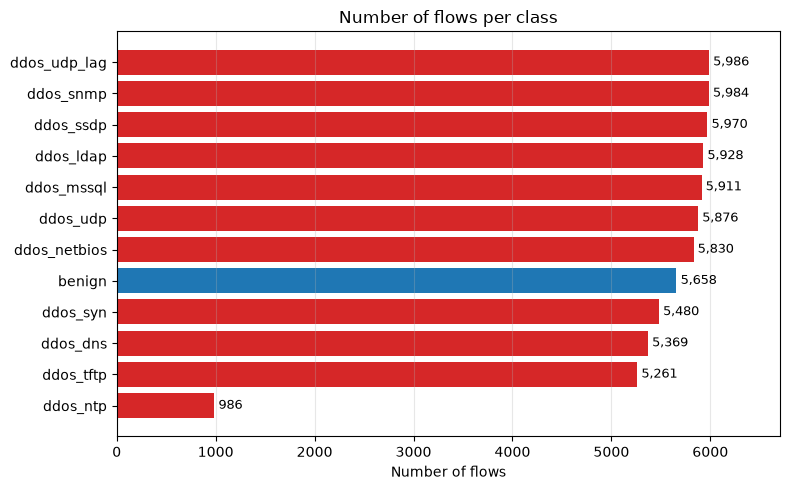

,Flows,%
label,,
ddos_udp_lag,5986,9.32
ddos_snmp,5984,9.32
ddos_ssdp,5970,9.29
ddos_ldap,5928,9.23
ddos_mssql,5911,9.20
ddos_udp,5876,9.15
ddos_netbios,5830,9.08
benign,5658,8.81
ddos_syn,5480,8.53


Largest / smallest class: ddos_udp_lag (5,986) / ddos_ntp (986), ratio 6.1


In [22]:
counts = df["label"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(counts.index, counts.values,
               color=[BENIGN_COLOR if l == "benign" else ATTACK_COLOR for l in counts.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3, fontsize=9)
ax.set_xlim(0, counts.max() * 1.12)
ax.set_xlabel("Number of flows")
ax.set_title("Number of flows per class")
ax.grid(axis="x", alpha=0.3)
show_figure(fig, ANALYSIS, "02_flows_per_class")

table = counts.sort_values(ascending=False).to_frame("Flows")
table["%"] = (100 * table["Flows"] / len(df)).round(2)
save_table(table.rename_axis("Class").reset_index(), ANALYSIS, "02_flows_per_class",
           caption="Number of flows per class.", label="tab:flows_per_class")

display(table)
print(f"Largest / smallest class: {counts.idxmax()} ({counts.max():,}) / "
      f"{counts.idxmin()} ({counts.min():,}), ratio {counts.max() / counts.min():.1f}")

The plot makes the imbalance visible: the largest class (`ddos_udp_lag`, 5,986 flows) is 6.1 times the smallest (`ddos_ntp`, 986). Benign traffic is only 8.8% of the dataset, so a model that always answered "attack" would be right 91% of the time: as a binary benign/attack measure, accuracy says little here.

### 4.3 Source and destination IPs: how concentrated is the traffic?

ECDF of the number of flows per IP address (log scale), with the busiest address highlighted, and the five busiest addresses in each role.

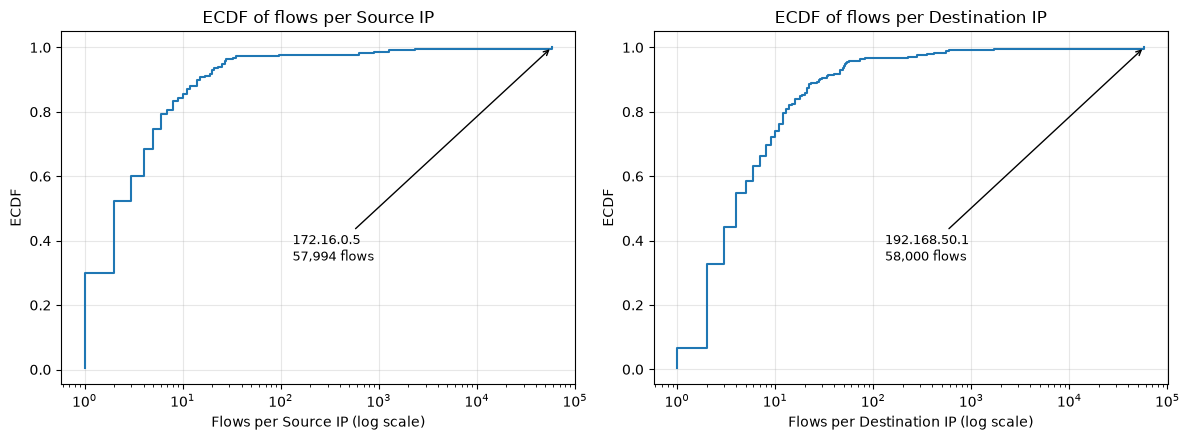

,role,ip,flows,%,main classes
0,Source IP,172.16.0.5,57994,90.28,"ddos_udp_lag, ddos_snmp, ddos_ssdp"
1,Source IP,192.168.50.7,2342,3.65,benign
2,Source IP,192.168.50.6,1279,1.99,benign
3,Source IP,192.168.50.8,892,1.39,benign
4,Source IP,192.168.50.1,626,0.97,"ddos_ntp, ddos_dns, benign"
5,Destination IP,192.168.50.1,58000,90.29,"ddos_udp_lag, ddos_snmp, ddos_ssdp"
6,Destination IP,4.2.2.4,1713,2.67,benign
7,Destination IP,172.16.0.5,587,0.91,"ddos_ntp, ddos_dns, ddos_ldap"
8,Destination IP,192.168.50.7,547,0.85,benign
9,Destination IP,8.8.8.8,419,0.65,benign


Distinct Source IP per class: benign 215, attacks from 1 to 2
Distinct Destination IP per class: benign 244, attacks from 1 to 2


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_rows = []
for ax, col in zip(axes, ["Source IP", "Destination IP"]):
    per_ip = df[col].value_counts()
    x = np.sort(per_ip.values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post")
    ax.set_xscale("log")
    ax.set_xlabel(f"Flows per {col} (log scale)")
    ax.set_ylabel("ECDF")
    ax.set_title(f"ECDF of flows per {col}")
    ax.grid(alpha=0.3)
    ax.annotate(f"{per_ip.index[0]}\n{per_ip.iloc[0]:,} flows",
                xy=(per_ip.iloc[0], 1), xytext=(0.45, 0.35), textcoords="axes fraction",
                arrowprops=dict(arrowstyle="->"), fontsize=9)
    for ip, n in per_ip.head(5).items():
        classes = ", ".join(df.loc[df[col] == ip, "label"].value_counts().index[:3])
        top_rows.append({"role": col, "ip": ip, "flows": n,
                         "%": round(100 * n / len(df), 2), "main classes": classes})
show_figure(fig, ANALYSIS, "03_ecdf_flows_per_ip")
top_ips = pd.DataFrame(top_rows)

display(top_ips)
for col in ["Source IP", "Destination IP"]:
    per_class = df.groupby("label")[col].nunique()
    print(f"Distinct {col} per class: benign {per_class['benign']}, "
          f"attacks from {per_class.drop('benign').min()} to {per_class.drop('benign').max()}")

Both ECDFs rise steeply: most addresses appear in a handful of flows, while a single address on each side covers about 90% of the dataset (172.16.0.5 as source, 192.168.50.1 as destination). Apart from these two, the busiest addresses are benign hosts of the internal network (192.168.50.6–8) and public DNS servers (4.2.2.4 and 8.8.8.8).

Every attack class uses at most 2 source and 2 destination IPs, the two ends of the same conversation, while benign traffic involves 215 sources and 244 destinations. A model given the IP addresses would learn "172.16.0.5 → 192.168.50.1 means attack" instead of how the attacks behave. This is why the IPs are removed (ESCL, §8.3).

### 4.4 Transport protocols per class

`Protocol` is the IANA protocol number: 6 = TCP, 17 = UDP; 0 is mapped to "other".

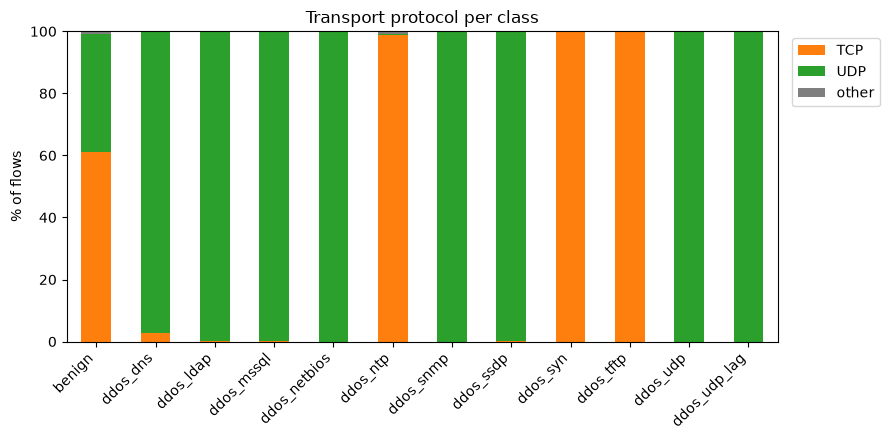

Overall: UDP 76.1%, TCP 23.8%, other 0.1%


transport,TCP,UDP,other
label,,,
benign,61.0,38.2,0.7
ddos_dns,2.6,97.3,0.1
ddos_ldap,0.0,99.9,0.0
ddos_mssql,0.0,100.0,0.0
ddos_netbios,0.0,100.0,0.0
ddos_ntp,98.7,0.6,0.7
ddos_snmp,0.0,100.0,0.0
ddos_ssdp,0.1,99.9,0.0
ddos_syn,100.0,0.0,0.0


In [24]:
proto = pd.crosstab(df["label"], df["transport"], normalize="index").reindex(LABELS) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
proto.plot(kind="bar", stacked=True, ax=ax,
           color={"TCP": "#ff7f0e", "UDP": "#2ca02c", "other": "#7f7f7f"})
ax.set_ylabel("% of flows")
ax.set_xlabel("")
ax.set_title("Transport protocol per class")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
show_figure(fig, ANALYSIS, "04_protocol_per_class")

print("Overall: " + ", ".join(f"{p} {v:.1%}" for p, v in proto_pct.items()))
display(proto.round(1))

Most attack classes are almost pure UDP (from 97.3% for `ddos_dns` to 100%). `ddos_syn` is entirely TCP, as expected for a SYN flood, and benign traffic is mixed (61% TCP, 38% UDP).

Two classes do not match their name. NTP and TFTP amplification attacks run over UDP, yet `ddos_ntp` is 98.7% TCP and `ddos_tftp` 99.9% TCP. §7.8 shows that neither class contains a single flow on the NTP (123) or TFTP (69) port. These labels seem to reflect the capture in which the flows were recorded (§7.1) rather than their content, a point worth discussing in the report.

### 4.5 Time evolution

Two views of the same information: a timeline with one dot per flow and one row per class, and the number of flows per minute (log scale). The second plot uses dots only: between one burst and the next there are no flows, so lines would be misleading.

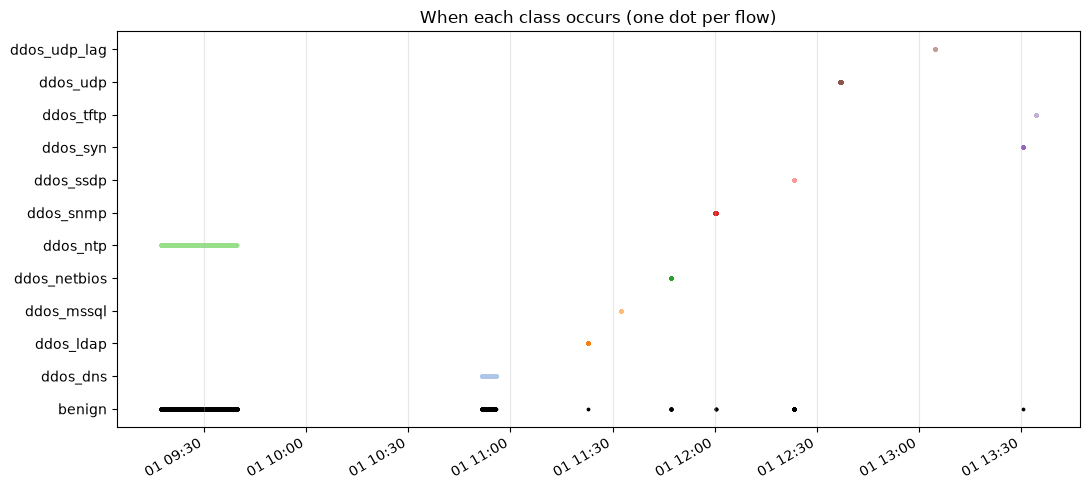

In [25]:
# 5a. timeline: one dot per flow, one row per class
fig, ax = plt.subplots(figsize=(11, 5))
for i, lab in enumerate(LABELS):
    ts = df.loc[df["label"] == lab, "Timestamp"]
    ax.scatter(ts, np.full(len(ts), i), s=3, color=CLASS_C[lab])
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
ax.set_title("When each class occurs (one dot per flow)")
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
show_figure(fig, ANALYSIS, "05a_timeline")

Each class occupies its own moment of the day. The attacks appear one after the other, most of them as a single dot (a burst of about a second), `ddos_ntp` and `ddos_dns` as short bars. Benign flows are not spread over the day either: they form two bars, together with `ddos_ntp` and `ddos_dns`, plus a few isolated dots at the time of other attacks (§7.1 explains why). The next plot counts the flows per minute, on a log scale because the counts go from 1 to several thousand, and the table gives the exact window of each class.

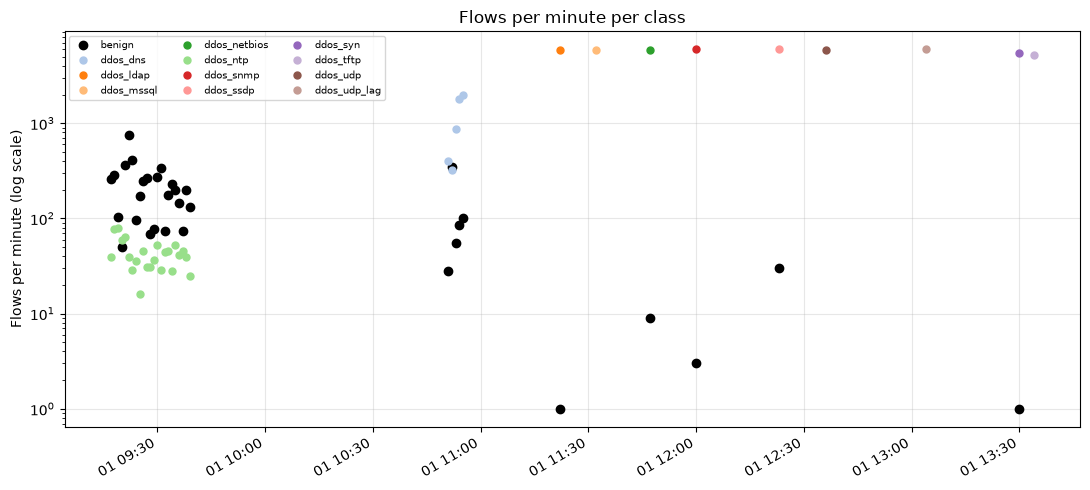

,min,max,duration
label,,,
ddos_ntp,09:17:11,09:39:32,00:22:21.714565
benign,09:17:12,13:30:30,04:13:18.107533
ddos_dns,10:51:39,10:55:44,00:04:04.863597
ddos_ldap,11:22:40,11:22:41,00:00:01.689571
ddos_mssql,11:32:32,11:32:34,00:00:01.770705
ddos_netbios,11:47:08,11:47:09,00:00:00.843774
ddos_snmp,12:00:13,12:00:14,00:00:00.803852
ddos_ssdp,12:23:13,12:23:14,00:00:00.718002
ddos_udp,12:36:57,12:36:58,00:00:00.792066


In [26]:
# 5b. flows per minute, log y axis; dots only, no lines:
#     between one activity and the next there are no flows
fig, ax = plt.subplots(figsize=(11, 5))
for lab in LABELS:
    per_min = df.loc[df["label"] == lab, "Timestamp"].dt.floor("1min").value_counts().sort_index()
    ax.plot(per_min.index, per_min.values, ls="none", marker="o",
            ms=6 if lab == "benign" else 5, color=CLASS_C[lab], label=lab)
ax.set_yscale("log")
ax.set_ylabel("Flows per minute (log scale)")
ax.set_title("Flows per minute per class")
ax.legend(fontsize=7, ncol=3)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
show_figure(fig, ANALYSIS, "05b_flows_per_minute")

windows = df.groupby("label")["Timestamp"].agg(["min", "max"]).sort_values("min")
windows["duration"] = (windows["max"] - windows["min"]).astype(str).str.replace("0 days ", "")
display(windows.assign(min=windows["min"].dt.strftime("%H:%M:%S"),
                       max=windows["max"].dt.strftime("%H:%M:%S")))

The attack windows never overlap: `ddos_ntp` from 09:17 to 09:39, then DNS (10:51–10:55), LDAP, MSSQL, NetBIOS, SNMP, SSDP, UDP, UDP-lag and SYN, with TFTP last at 13:34. Apart from NTP (22 min) and DNS (4 min), every attack lasts less than 2 seconds: in the per-minute plot it is a single point with more than 5,000 flows, a thin slice of a flood (§7.1). Benign traffic stays below 1,000 flows per minute and is concentrated in the NTP window and, to a lesser extent, in the DNS window.

This has two consequences:

- the timestamp alone identifies the class almost perfectly, so it cannot be a feature (ESCL);
- a split of the data by time would put entire classes only in the training set or only in the test set, which matters for the split of section 2.1b of the assignment.

### 4.6 Services in benign traffic

The service is inferred from the lower of the two ports of the flow, looked up in a small table of well-known ports.

In [27]:
SERVICES = {53: "DNS", 80: "HTTP", 443: "HTTPS", 465: "SMTPS", 21: "FTP", 22: "SSH",
            67: "DHCP", 123: "NTP", 137: "NetBIOS", 138: "NetBIOS"}
benign = df[df["label"] == "benign"]
service = benign[["Source Port", "Destination Port"]].min(axis=1).map(SERVICES).fillna("other")
services = pd.crosstab(service.rename("Service"), benign["transport"])
services = services.loc[services.sum(axis=1).sort_values(ascending=False).index]
save_table(services.reset_index(), ANALYSIS, "06_benign_services",
           caption="Application services in benign traffic, inferred from well-known ports.",
           label="tab:benign_services")

display(services)

transport,TCP,UDP,other
Service,,,
HTTPS,2312,0,0
DNS,0,2132,0
HTTP,1098,0,0
other,0,18,40
SMTPS,32,0,0
DHCP,0,8,0
FTP,7,0,0
SSH,5,0,0
NTP,0,3,0


Benign traffic is ordinary client activity: HTTPS (2,312 flows) and HTTP (1,098) over TCP, DNS over UDP (2,132), and a few flows of mail (SMTPS), DHCP, FTP, SSH, NTP and NetBIOS. The "other" row holds the 40 benign flows with protocol 0 and 18 UDP flows on ports outside the table.

## 5. Constant, identical and correlated columns

This section looks for useless or redundant columns, without modifying the dataset:

1. constant columns (a single value in every row);
2. identical columns (the same values row by row);
3. pairs of features whose Pearson correlation is above 0.95 in absolute value;
4. the heatmap of the correlation matrix.

Analyses 2–4 use only the numeric *behaviour* features: constant columns and identifiers (Flow ID, IPs, Timestamp, ports, Protocol) are left out. Pearson's correlation measures only linear relations and is very sensitive to extreme values, and this section runs on the raw data, which contain the corrupted values of §7: §7.5 shows that a single impossible value is enough to hide a redundancy.

In [28]:
THRESHOLD = 0.95   # |correlation| above which two features are considered redundant
ANALYSIS = "correlation"

df = load_dataset()

### 5.1 Constant columns

In [29]:
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"CONSTANT COLUMNS ({len(const_cols)}):")
display(pd.DataFrame({"always =": [df[c].iloc[0] for c in const_cols]},
                     index=pd.Index(const_cols, name="column")))

# numeric "behaviour" features: constant columns and identifiers removed
ID_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp",
           "Source Port", "Destination Port", "Protocol"]
num = df.select_dtypes(include="number").drop(columns=const_cols + ID_COLS, errors="ignore")
print(f"Behaviour features used in §5.2-§5.4: {num.shape[1]}")

CONSTANT COLUMNS (12):


,always =
column,
Bwd PSH Flags,0
Fwd URG Flags,0
Bwd URG Flags,0
FIN Flag Count,0
PSH Flag Count,0
ECE Flag Count,0
Fwd Avg Bytes/Bulk,0
Fwd Avg Packets/Bulk,0
Fwd Avg Bulk Rate,0


Behaviour features used in §5.2-§5.4: 66


The same 12 constant columns as §3.7. Without them and without the identifiers, 66 numeric behaviour features remain, hence 66 × 65 / 2 = 2,145 pairs to compare. `SimillarHTTP` is not among them, because it is still a text column.

### 5.2 Identical columns

Two columns are reported when `Series.equals` finds the same values in every row. Note that `equals` also compares the data type, so two columns with the same numbers stored once as integers and once as floats are *not* reported here; they show up in §5.3 with correlation 1.000 (§8.2 checks them directly).

In [30]:
identical = []
cols = list(num.columns)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if num[a].equals(num[b]):
            identical.append((a, b))
print("IDENTICAL COLUMNS (exact duplicates):")
display(pd.DataFrame(identical, columns=["column", "identical to"]))

IDENTICAL COLUMNS (exact duplicates):


,column,identical to
0,Total Fwd Packets,Subflow Fwd Packets
1,Total Backward Packets,Subflow Bwd Packets
2,Fwd PSH Flags,RST Flag Count
3,Fwd Header Length,Fwd Header Length.1


Four pairs are exact copies:

- `Subflow Fwd Packets` and `Subflow Bwd Packets` repeat the packet totals: here CICFlowMeter's subflow statistics coincide with those of the whole flow;
- `Fwd Header Length.1` is the well-known duplicate column of CICFlowMeter's output, corrupted values included;
- `RST Flag Count` equals `Fwd PSH Flags` in every row. Two different TCP flags cannot always coincide, so this is an artefact of the extractor, not a property of the traffic.

In each pair one column is removed and the other kept, except for the header-length pair, where both are removed because they are corrupted (§8.3).

### 5.3 Pairs with |correlation| > 0.95

In [31]:
corr = num.corr()
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (upper.stack().dropna()       # .dropna(): pandas >= 3 keeps the NaN of the lower half
         .sort_values(ascending=False)
         .rename("abs_corr").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
strong = pairs[pairs["abs_corr"] > THRESHOLD]
print(f"PAIRS WITH |correlation| > {THRESHOLD}: {len(strong)} (out of {len(pairs):,} pairs)")
display(strong.round(3))

PAIRS WITH |correlation| > 0.95: 51 (out of 2,145 pairs)


,feature_1,feature_2,abs_corr
0,Total Backward Packets,Subflow Bwd Packets,1.000
1,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000
2,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000
3,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000
4,Fwd PSH Flags,RST Flag Count,1.000
5,Fwd Header Length,Fwd Header Length.1,1.000
6,Total Fwd Packets,Subflow Fwd Packets,1.000
7,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000
8,Fwd Packet Length Min,Min Packet Length,1.000
9,Flow Duration,Fwd IAT Total,1.000


51 of the 2,145 pairs exceed 0.95. They form a few families:

- **subflow statistics** equal to the flow totals;
- **forward inter-arrival times** almost equal to those of the whole flow (`Fwd IAT Total`–`Flow Duration` 1.000; the other `Fwd IAT` statistics from 0.986 to 0.999), because most flows have no backward packets;
- **packet-size measures** (`Fwd Packet Length Mean/Min/Max`, `Min Packet Length`, `Packet Length Mean`, `Average Packet Size`, `Avg Fwd Segment Size`): in one-directional flows of identical packets they are nearly the same number;
- **idle times**, close to `Flow IAT Max`;
- **rates**, with `Fwd Packets/s` against `Flow Packets/s`.

Two pairs with correlation 1.000 are exact copies that §5.2 misses, because one column is stored as integers and the other as floats: `Total Length of Fwd Packets`–`Subflow Fwd Bytes` and `Total Length of Bwd Packets`–`Subflow Bwd Bytes` (§8.2 checks them). The list comes from the raw data, and the corrupted values change some of these correlations (§7.5).

### 5.4 Correlation heatmap

Red = positive correlation, blue = negative, white = none (scale from −1 to +1).

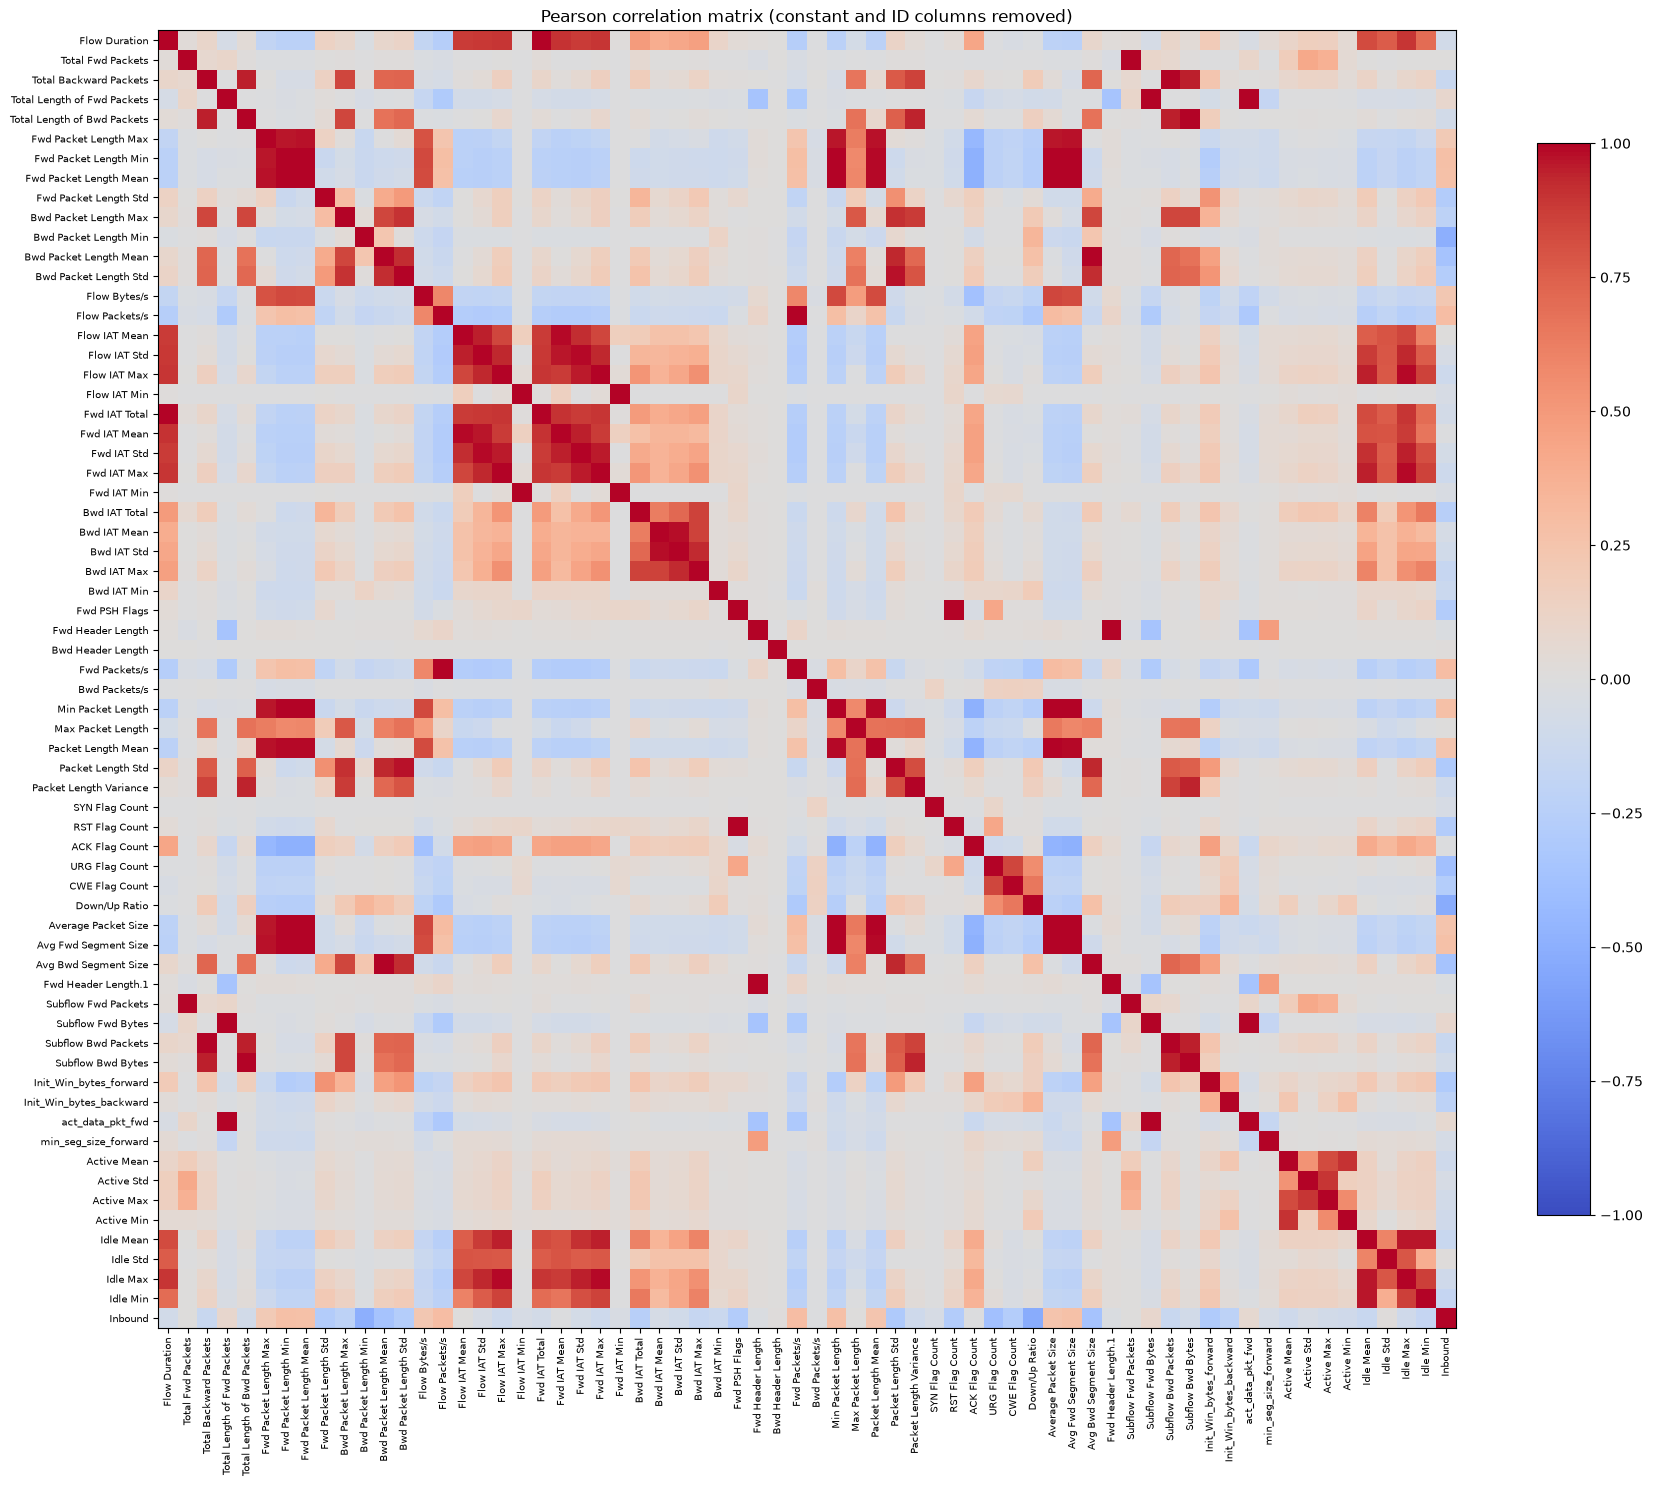

In [32]:
fig, ax = plt.subplots(figsize=(18, 15))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Pearson correlation matrix (constant and ID columns removed)")
fig.colorbar(im, ax=ax, shrink=0.8)
show_figure(fig, ANALYSIS, "correlation_heatmap")

The heatmap shows the same families as red blocks: inter-arrival and idle times, packet sizes, backward-direction statistics, and the `Active` statistics. Strongly negative correlations are rare. The rows of `Fwd Header Length`, `min_seg_size_forward` and `Bwd Header Length` are almost uniformly pale: their corrupted values make them look unrelated to everything else, apart from each other and from the copy `Fwd Header Length.1` (§7.5).

## 6. Ground-truth level

Here the 12 classes are compared with each other, feature by feature:

1. a summary table per class (IPs, ports, protocol, medians);
2. ports: ECDF of source and destination ports, heatmaps of the most frequent ones;
3. distribution of nine key features: ECDF and boxplots per class;
4. average TCP flags per class;
5. the "fingerprint" of each class (normalised medians);
6. benign traffic against all the attacks together.

Most of these features span several orders of magnitude, so the plots use a log scale after adding 1 (to keep the zeros). None of the nine key features is among the corrupted columns of §7, so these plots are not affected by them.

In [33]:
ANALYSIS = "gt_level"

df = load_dataset()
LABELS = class_order(df)
COLORS = class_colors(LABELS)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

KEY_FEATURES = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Packet Length Mean", "Flow Bytes/s",
    "Flow Packets/s", "Flow IAT Mean", "Init_Win_bytes_forward",
]

def ecdf(values):
    x = np.sort(np.asarray(values, dtype=float))
    return x, np.arange(1, len(x) + 1) / len(x)

def plot_ecdf_per_class(ax, feature, logx=True):
    """ECDF of a feature, one curve per class. With logx, 1 is added so that
    the log scale can be used even with zero values."""
    for lab in LABELS:
        v = df.loc[df["label"] == lab, feature].dropna()
        if logx:
            v = v + 1
        x, y = ecdf(v)
        ax.plot(x, y, label=lab, color=COLORS[lab],
                lw=2.2 if lab == "benign" else 1.2, ls="--" if lab == "benign" else "-")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(feature + (" (+1, log scale)" if logx else ""))
    ax.set_ylabel("ECDF")
    ax.grid(alpha=0.3)

### 6.1 Per-class summary

Number of flows, distinct IPs and ports, share of UDP flows and the medians of duration (µs), forward and backward packets and mean packet length (bytes).

In [34]:
summary = df.groupby("label").agg(
    flows=("label", "size"),
    src_ips=("Source IP", "nunique"),
    dst_ips=("Destination IP", "nunique"),
    src_ports=("Source Port", "nunique"),
    dst_ports=("Destination Port", "nunique"),
    pct_udp=("Protocol", lambda s: (s == 17).mean() * 100),
    median_duration=("Flow Duration", "median"),
    median_fwd_pkts=("Total Fwd Packets", "median"),
    median_bwd_pkts=("Total Backward Packets", "median"),
    median_pkt_len=("Packet Length Mean", "median"),
).reindex(LABELS).round(1)
display(summary)

report_table = summary[["flows", "src_ips", "dst_ips", "pct_udp", "median_duration",
                        "median_fwd_pkts", "median_bwd_pkts", "median_pkt_len"]]
report_table.columns = ["Flows", "Src IPs", "Dst IPs", "UDP %", "Duration (µs)",
                        "Fwd pkts", "Bwd pkts", "Pkt len (B)"]
save_table(report_table.rename_axis("Class").reset_index(), ANALYSIS, "01_per_class_summary",
           caption="Per-class summary (medians for duration, packets and packet length).",
           label="tab:per_class_summary", float_format="%.0f", compact=True)

,flows,src_ips,dst_ips,src_ports,dst_ports,pct_udp,median_duration,median_fwd_pkts,median_bwd_pkts,median_pkt_len
label,,,,,,,,,,
benign,5658,215,244,2725,893,38.2,20822.0,2.0,2.0,44.2
ddos_dns,5369,2,2,553,4879,97.3,28301.0,200.0,0.0,440.0
ddos_ldap,5928,2,2,368,5693,99.9,1.0,2.0,0.0,1472.0
ddos_mssql,5911,2,2,521,5619,100.0,1.0,2.0,0.0,1472.0
ddos_netbios,5830,2,2,4901,5528,100.0,1.0,2.0,0.0,483.0
ddos_ntp,986,2,2,349,341,0.6,210.5,1.0,2.0,0.0
ddos_snmp,5984,2,2,511,5704,100.0,1.0,2.0,0.0,229.0
ddos_ssdp,5970,2,2,515,5686,99.9,2.0,2.0,0.0,1472.0
ddos_syn,5480,1,1,5274,4927,0.0,51.0,2.0,0.0,0.0


The per-class table already separates several groups:

- **benign** is the only class with many hosts (215 sources, 244 destinations); together with `ddos_ntp`, it is also the only one with backward packets (median 2);
- **`ddos_ldap`, `ddos_mssql` and `ddos_ssdp`** look alike: 1–2 µs flows of 2 packets of 1,472 bytes. `ddos_snmp` and `ddos_netbios` are similar, with smaller packets (229 and 483 bytes);
- **`ddos_dns`** has longer flows (median 28 ms) of 200 forward packets of 440 bytes; **`ddos_udp`** long flows (105 ms) of 4 packets;
- **`ddos_syn` and `ddos_tftp`** are TCP flows without payload (median packet length 0), differing mainly in duration (51 µs against 1 µs);
- **ports.** `ddos_dns`, `ddos_ldap`, `ddos_mssql`, `ddos_snmp` and `ddos_ssdp` use few source ports (368–553) and thousands of destination ports. `ddos_netbios`, `ddos_syn`, `ddos_tftp`, `ddos_udp` and `ddos_udp_lag` use thousands of both.

### 6.2 Ports

ECDF of source and destination ports per class (linear scale), then the share of each class's flows on the 20 most frequent ports overall, for destination and source ports.

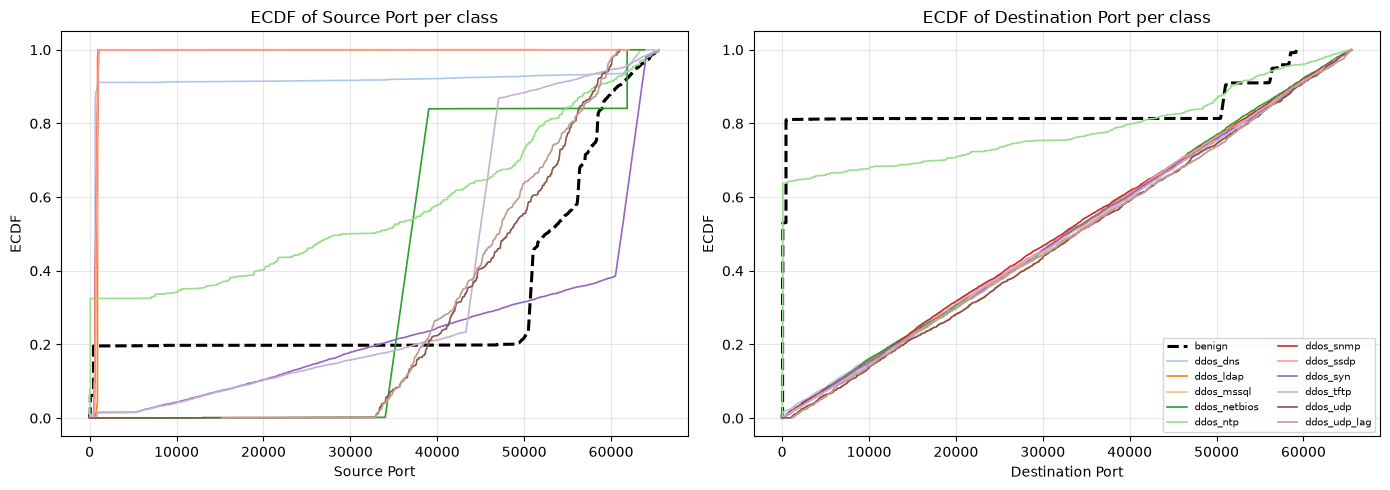

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Source Port", "Destination Port"]):
    plot_ecdf_per_class(ax, col, logx=False)
    ax.set_title(f"ECDF of {col} per class")
axes[1].legend(fontsize=7, ncol=2)
show_figure(fig, ANALYSIS, "01_ecdf_ports")

The two ECDFs show two different kinds of port:

- **destination ports (right):** for every attack class except `ddos_ntp` the curve is a straight diagonal from 0 to 65,535, the signature of a port drawn at random. Benign traffic instead reaches about 0.8 already at the low service ports, and `ddos_ntp` about 0.64;
- **source ports (left):** `ddos_ldap`, `ddos_mssql`, `ddos_snmp` and `ddos_ssdp` jump to 1 within the first thousand ports, and `ddos_dns` to about 0.9. The floods and `ddos_netbios` sit mostly in the upper half of the range, and benign clients mostly above 50,000.

The two heatmaps that follow show which ports these are: for each class, the share of its flows on each of the 20 most frequent ports of the dataset, destination first, then source.

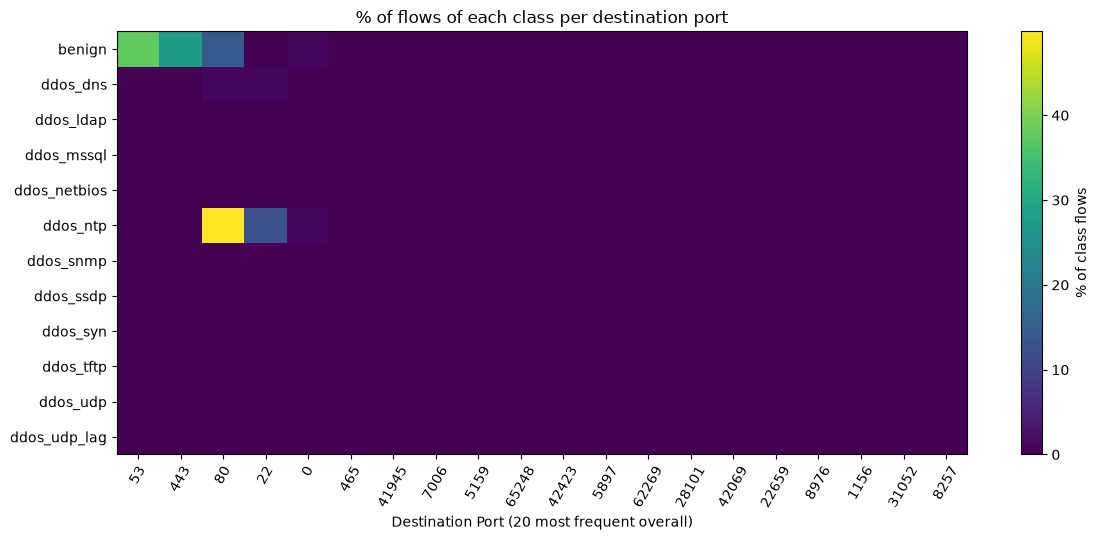

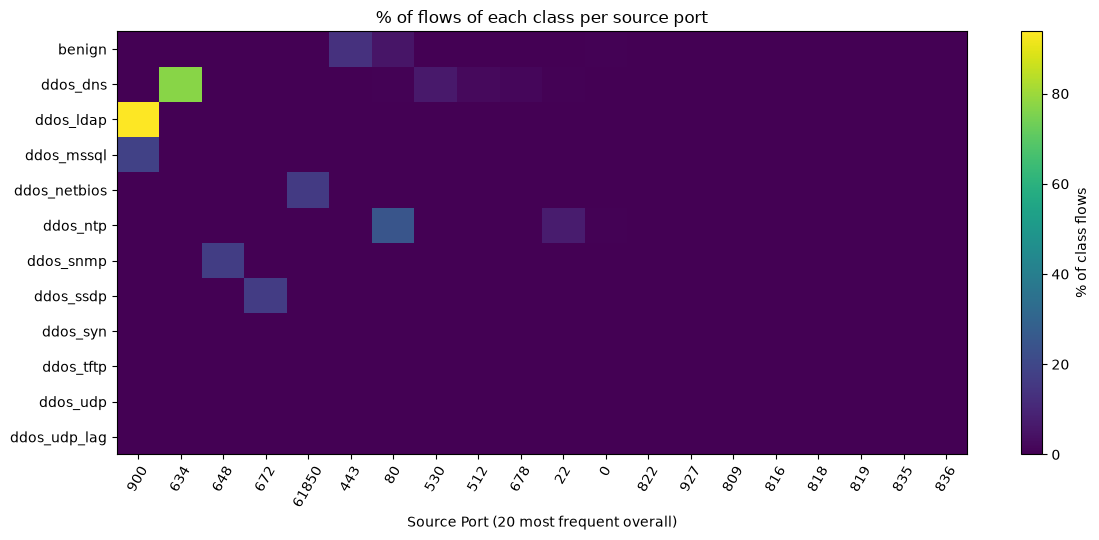

In [36]:
for col, name in [("Destination Port", "02_heatmap_dst_ports"),
                  ("Source Port", "03_heatmap_src_ports")]:
    top_ports = df[col].value_counts().head(20).index
    heat = (pd.crosstab(df["label"], df[col], normalize="index")
            .reindex(index=LABELS, columns=top_ports, fill_value=0) * 100)
    fig, ax = plt.subplots(figsize=(12, 5.5))
    im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(top_ports)))
    ax.set_xticklabels(top_ports, rotation=60)
    ax.set_yticks(range(len(LABELS)))
    ax.set_yticklabels(LABELS)
    ax.set_xlabel(f"{col} (20 most frequent overall)")
    ax.set_title(f"% of flows of each class per {col.lower()}")
    fig.colorbar(im, ax=ax, label="% of class flows")
    show_figure(fig, ANALYSIS, name)

**Destination ports** (first heatmap): benign traffic goes mostly to DNS (53), HTTPS (443) and HTTP (80). Half of the `ddos_ntp` flows go to port 80 and others to 22, i.e. web and SSH rather than NTP. The other attack classes barely appear: their destination ports are random, so no single port collects a visible share of their flows.

**Source ports** (second heatmap) separate the classes in a different way:

- each reflection class has its own fixed low port: 900 for 94% of `ddos_ldap` and 18% of `ddos_mssql`, 634 for 77% of `ddos_dns`, 648 for `ddos_snmp`, 672 for `ddos_ssdp`;
- `ddos_netbios` uses port 61850 in 16% of its flows;
- `ddos_ntp` shows ports 80 and 22 again, for the flows in the opposite direction;
- benign shows the server ports 443 and 80 (replies from servers), while the floods have no recurring port.

None of these is the port of the abused service (§7.8): they are choices of the attack tools. This is the starting point of the `Source Port` discussion in §8.5.

### 6.3 Distribution of the key features

ECDFs first (one curve per class, benign dashed), then boxplots of the same features with the outliers hidden.

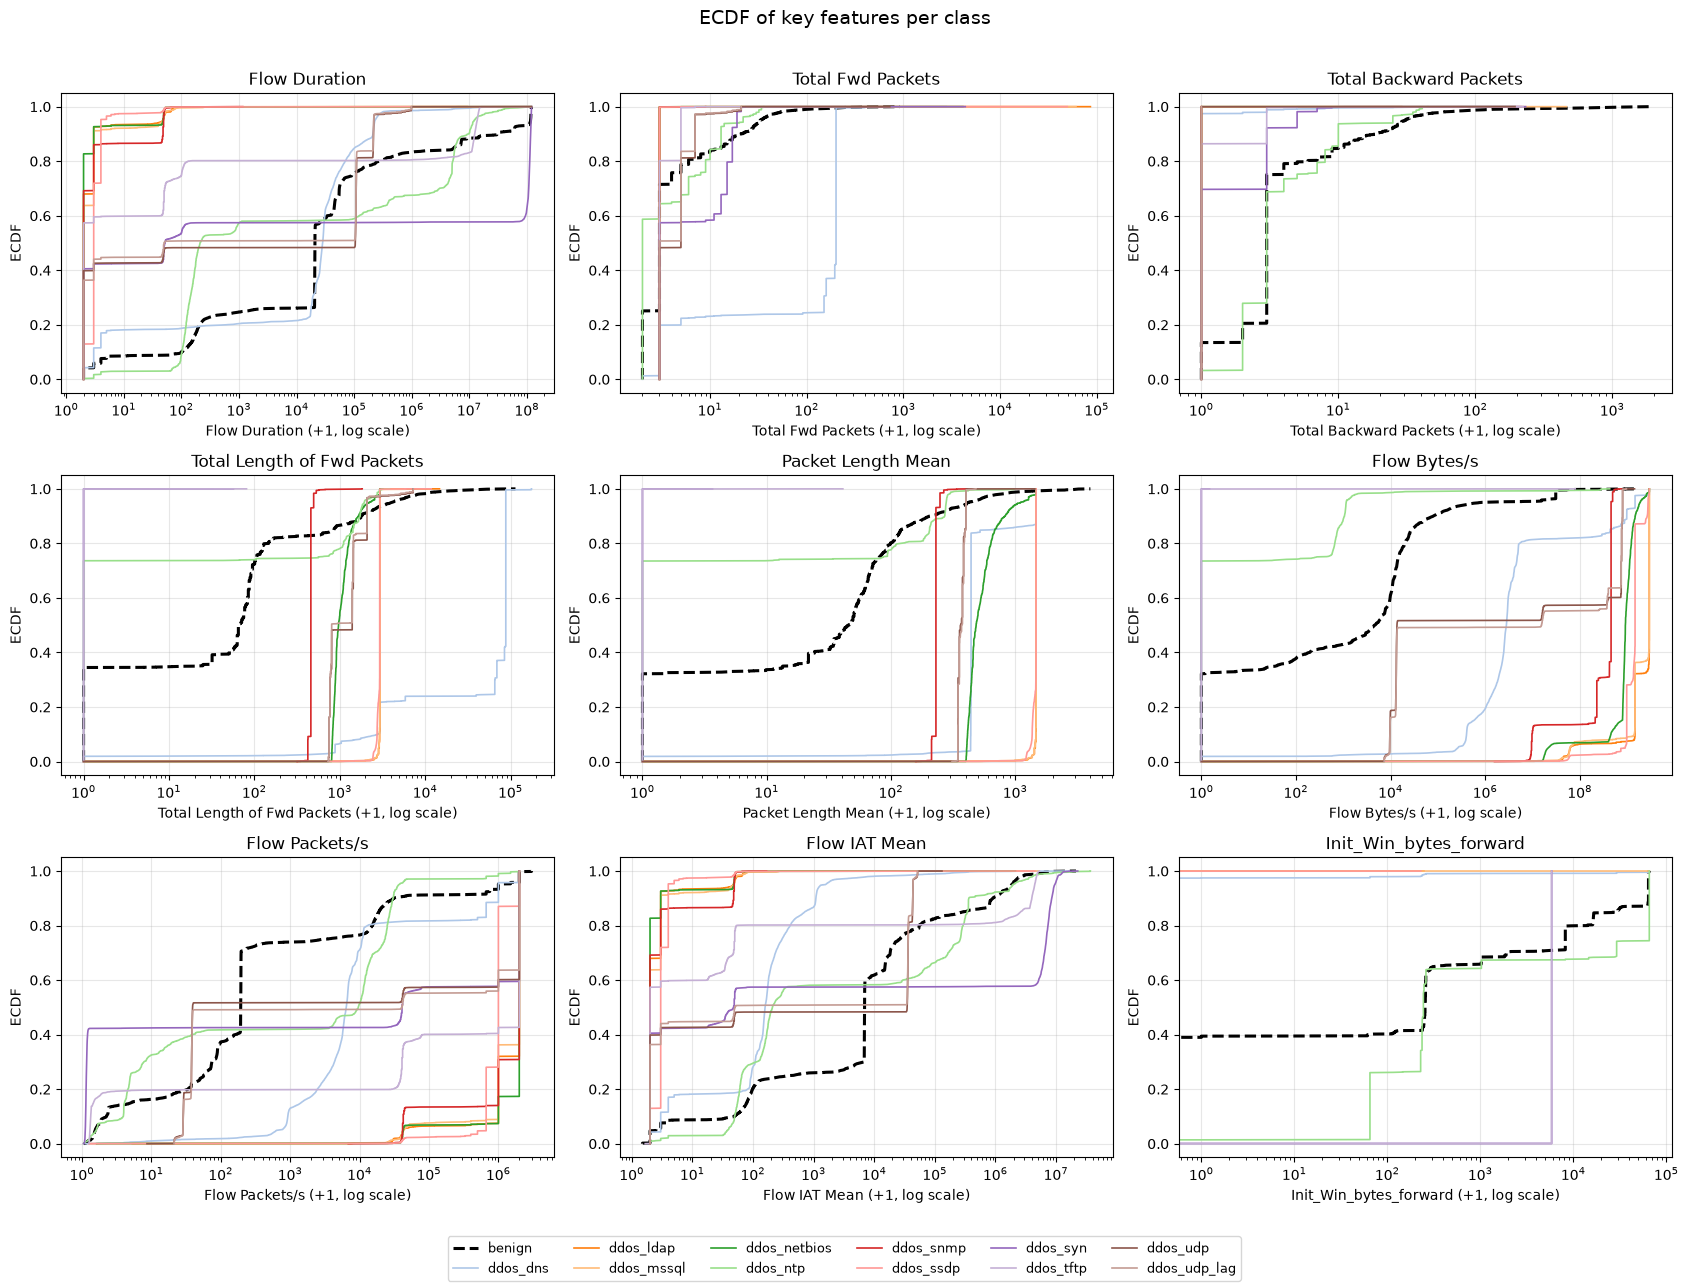

In [37]:
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, feat in zip(axes.ravel(), KEY_FEATURES):
    plot_ecdf_per_class(ax, feat)
    ax.set_title(feat)
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=6, fontsize=9)
fig.suptitle("ECDF of key features per class", fontsize=14)
fig.tight_layout(rect=[0, 0.05, 1, 0.97])
show_figure(fig, ANALYSIS, "04_ecdf_key_features", tight=False)

Some features separate classes on their own:

- **`Flow Duration`**: `ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_snmp` and `ddos_ssdp` are made almost entirely of 1–2 µs flows, while benign and `ddos_dns` flows last from milliseconds to seconds. `ddos_syn` is bimodal: its median is 51 µs, but a large share of its flows last about 100 s;
- **`Total Fwd Packets`**: most `ddos_dns` flows have exactly 200 forward packets;
- **`Total Backward Packets`**: only benign and `ddos_ntp` flows mostly have backward packets; a minority of `ddos_syn` and `ddos_tftp` flows have some;
- **`Packet Length Mean`** and **`Total Length of Fwd Packets`** order the UDP classes by packet size (229 B SNMP, 440 B DNS, 483 B NetBIOS, 1,472 B LDAP, MSSQL and SSDP), while `ddos_syn` and `ddos_tftp` carry no payload;
- **`Flow Bytes/s`**: benign stays around 10⁴ B/s, the volumetric attacks reach 10⁸–10⁹ B/s;
- **`Init_Win_bytes_forward`**: only the TCP classes appear. For UDP the value is −1, which becomes 0 after adding 1 and cannot be drawn on a log axis, so those curves sit at 1 from the left edge.

The same nine features as boxplots, on a log scale after adding 1 and with the outliers hidden: each box spans the central half of the class, and the orange line is its median.

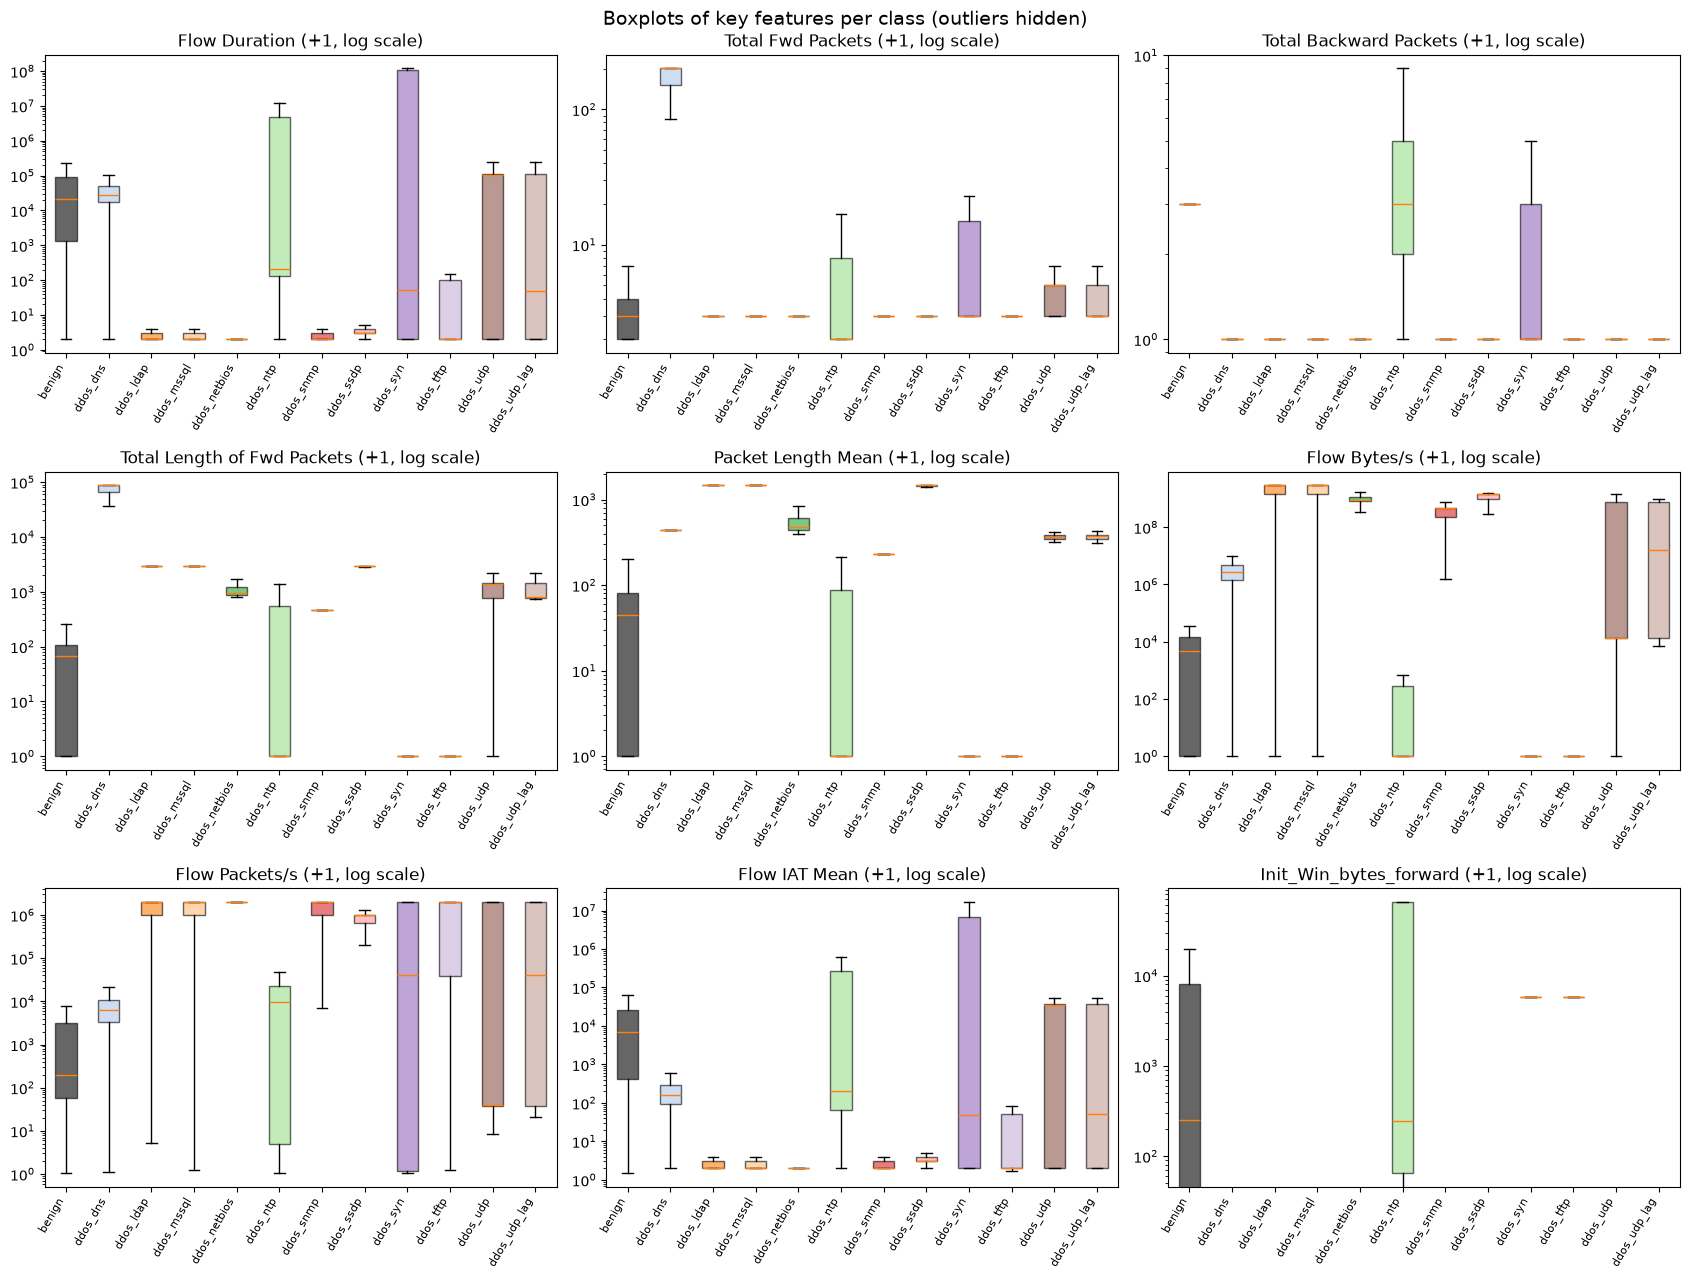

In [38]:
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, feat in zip(axes.ravel(), KEY_FEATURES):
    data = [df.loc[df["label"] == l, feat].dropna() + 1 for l in LABELS]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for patch, l in zip(bp["boxes"], LABELS):
        patch.set_facecolor(COLORS[l])
        patch.set_alpha(0.6)
    ax.set_yscale("log")
    ax.set_xticks(range(1, len(LABELS) + 1))
    ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8)
    ax.set_title(feat + " (+1, log scale)")
fig.suptitle("Boxplots of key features per class (outliers hidden)", fontsize=14)
show_figure(fig, ANALYSIS, "05_boxplots_key_features")

The boxplots show how homogeneous each class is. For `ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_snmp` and `ddos_ssdp` many boxes collapse to a single line: almost every flow has the same packet size, length and rate. These classes are easy to tell from the others but hard to tell from each other. Benign, `ddos_ntp`, `ddos_syn`, `ddos_udp` and `ddos_udp_lag` have wide boxes instead, and `ddos_syn` and `ddos_tftp` have an `Init_Win_bytes_forward` of 5,840 in almost every flow.

### 6.4 TCP flags per class

Mean of each flag column per class; since the flags are 0/1 here, the mean is the fraction of flows with the flag set. Only the non-constant flags are shown.

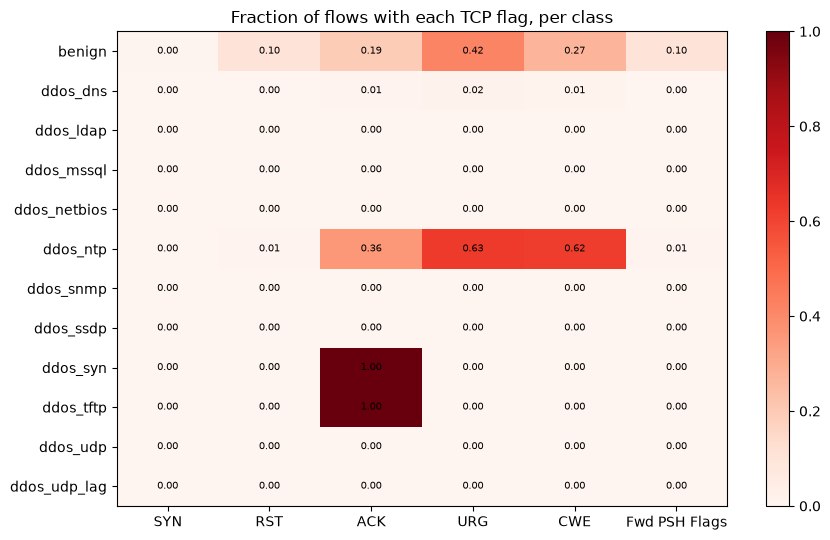

In [39]:
FLAGS = [f for f in ["SYN Flag Count", "RST Flag Count", "ACK Flag Count",
                     "URG Flag Count", "CWE Flag Count", "Fwd PSH Flags"]
         if f not in const_cols]
flags = df.groupby("label")[FLAGS].mean().reindex(LABELS)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(flags.values, cmap="Reds", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(FLAGS)))
ax.set_xticklabels([f.replace(" Flag Count", "") for f in FLAGS])
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
for i in range(flags.shape[0]):
    for j in range(flags.shape[1]):
        ax.text(j, i, f"{flags.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Fraction of flows with each TCP flag, per class")
fig.colorbar(im, ax=ax)
show_figure(fig, ANALYSIS, "06_tcp_flags")

- **SYN** is practically never set, not even in `ddos_syn` (0.00 in every class; 38 flows in the whole dataset). Instead, the SYN flood shows up as ACK = 1.00, exactly like `ddos_tftp`. The flag counters therefore do not follow TCP semantics and should be read as features produced by the tool.
- **RST and Fwd PSH** have the same value in every class (0.10 for benign, 0.01 for `ddos_ntp`), as expected, since the two columns are identical (§5.2).
- **URG and CWE** are set only in benign (0.42 and 0.27), `ddos_ntp` (0.63 and 0.62) and a few `ddos_dns` flows.
- **The UDP classes** are at 0, as expected.

### 6.5 Class fingerprint

For each class, the median of 14 features; medians are log-transformed and min-max normalised per column, so each column goes from the lowest class (blue) to the highest (red).

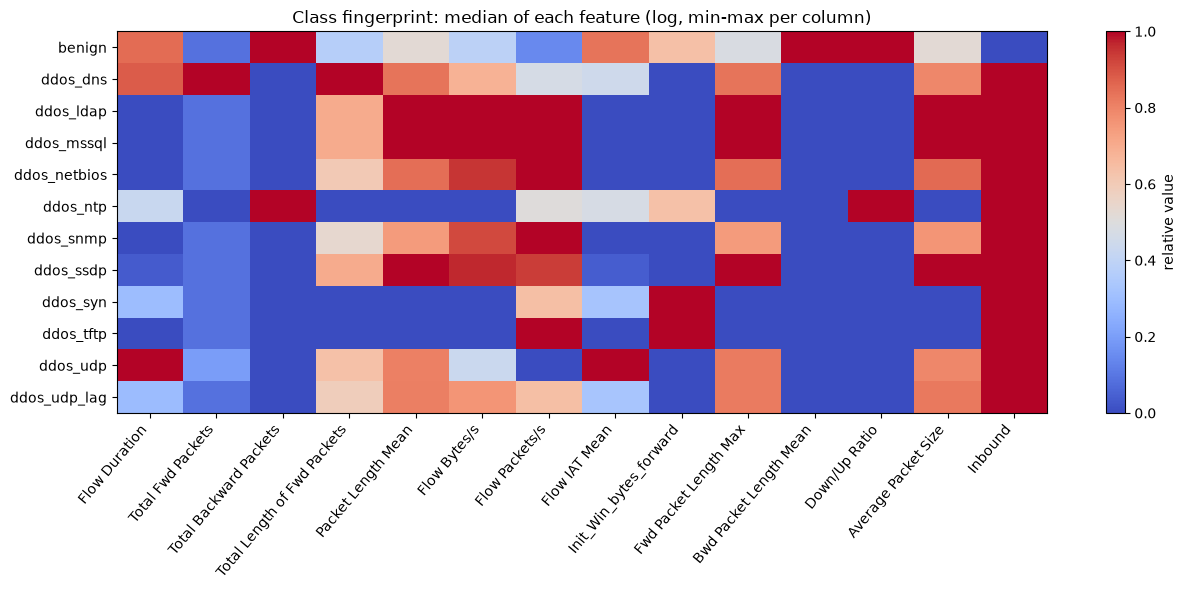

In [40]:
FINGER = KEY_FEATURES + ["Fwd Packet Length Max", "Bwd Packet Length Mean",
                         "Down/Up Ratio", "Average Packet Size", "Inbound"]
med = np.log1p(df.groupby("label")[FINGER].median().reindex(LABELS).clip(lower=0))
norm = (med - med.min()) / (med.max() - med.min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(norm.values, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(FINGER)))
ax.set_xticklabels(FINGER, rotation=50, ha="right")
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
ax.set_title("Class fingerprint: median of each feature (log, min-max per column)")
fig.colorbar(im, ax=ax, label="relative value")
show_figure(fig, ANALYSIS, "07_class_fingerprint")

Reading the heatmap by rows:

- **benign** is the only class with high `Bwd Packet Length Mean`, the only one with a median `Inbound` of 0, and, together with `ddos_ntp`, the only one with backward packets and a non-zero `Down/Up Ratio`;
- **`ddos_ldap` and `ddos_mssql`** have practically identical fingerprints, and `ddos_ssdp` is very close (short flows, large packets, very high rates);
- **`ddos_syn` and `ddos_tftp`** are also similar: TCP, no payload, high `Init_Win_bytes_forward`.

These groups of similar classes are where a classifier is most likely to confuse one attack with another.

### 6.6 Benign against all the attacks

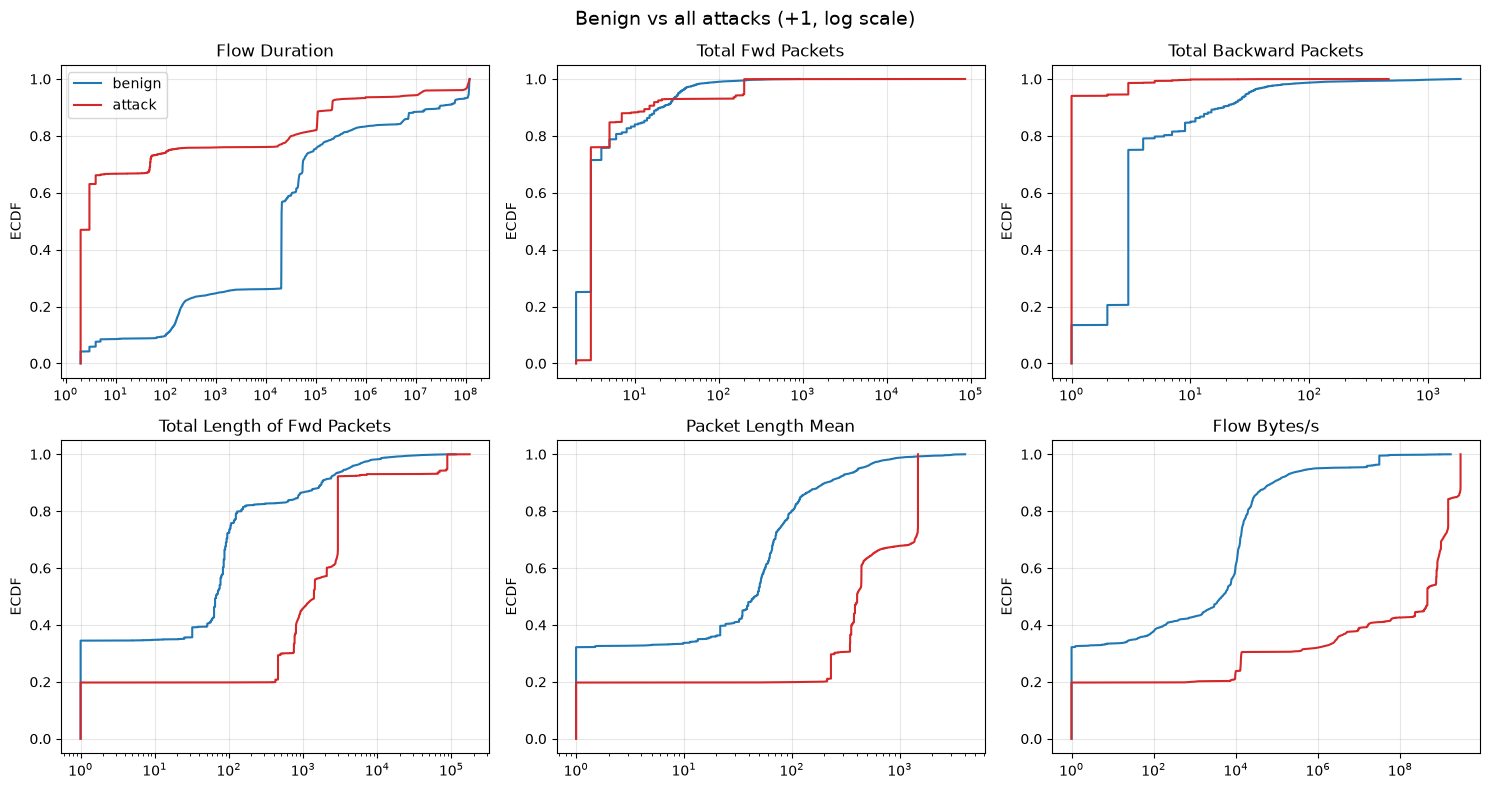

In [41]:
is_attack = df["label"] != "benign"
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), KEY_FEATURES[:6]):
    for mask, name, c in [(~is_attack, "benign", BENIGN_COLOR), (is_attack, "attack", ATTACK_COLOR)]:
        x, y = ecdf(df.loc[mask, feat].dropna() + 1)
        ax.plot(x, y, label=name, color=c)
    ax.set_xscale("log")
    ax.set_title(feat)
    ax.set_ylabel("ECDF")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Benign vs all attacks (+1, log scale)", fontsize=14)
show_figure(fig, ANALYSIS, "08_benign_vs_attack")

Taken together, the attacks differ from benign traffic on almost every feature:

- **duration:** most attack flows are a few microseconds long, while most benign flows last from tens of milliseconds upward;
- **backward packets:** more than 90% of attack flows have none, against a small minority of benign flows;
- **packet size and rate:** apart from the payload-free SYN and TFTP flows, attack packets are larger (from about 230 bytes up to 1,472), and the attack rates reach 10⁸–10⁹ B/s, against about 10⁴ for benign.

Only `Total Fwd Packets` is similar for the two groups. Telling benign from attack looks easy on this dataset; telling the attacks apart is the harder part (§6.5).

## 7. Anomalous values

This section documents, with numbers, the problems that the cleaning of §9 addresses, plus the unnamed index found in §2.4:

| § | Topic | Decision |
|---|---|---|
| 7.1 | the unnamed index column | not a column: nothing to remove |
| 7.2–7.4 | negative values in `Fwd Header Length` and `min_seg_size_forward` | both columns removed (CORR) |
| 7.5 | the single negative value of `Bwd Header Length` | that row removed |
| 7.6 | `Init_Win_bytes_forward/backward = −1` | kept: it means "not available" |
| 7.7 | `SimillarHTTP`, a text column with mixed types | turned into a 0/1 column |
| 7.8 | `Source Port` | still undecided (§8.5) |

In [42]:
ANALYSIS = "anomalies"

df = load_dataset()
LABELS = class_order(df)
TRANSPORT = df["Protocol"].map({6: "TCP", 17: "UDP", 0: "other"})

### 7.1 What the unnamed index column tells us

§2.4 showed that the first field of every row is an unnamed index, which pandas uses as row index. Its values are not just row numbers: they run from 0 to 65,999 with gaps, and they are grouped by class.

In [43]:
ids = df.index
print(f"Index values from {ids.min()} to {ids.max()}: {ids.max() + 1:,} possible ids, "
      f"{len(ids):,} rows, so {ids.max() + 1 - len(ids):,} ids are missing")
print("Increasing and without repetitions:", ids.is_monotonic_increasing and ids.is_unique)

blocks = pd.crosstab(ids // 6000, df["label"]).reindex(columns=LABELS, fill_value=0)
blocks.index = [f"{6000 * b:,}-{6000 * b + 5999:,}" for b in blocks.index]
blocks.index.name = "index ids"
blocks["rows"] = blocks[LABELS].sum(axis=1)
blocks["missing ids"] = 6000 - blocks["rows"]
display(blocks)

Index values from 0 to 65999: 66,000 possible ids, 64,239 rows, so 1,761 ids are missing
Increasing and without repetitions: True


label,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag,rows,missing ids
index ids,,,,,,,,,,,,,,
"0-5,999",615,5369,0,0,0,0,0,0,0,0,0,0,5984,16
"6,000-11,999",1,0,5928,0,0,0,0,0,0,0,0,0,5929,71
"12,000-17,999",0,0,0,5911,0,0,0,0,0,0,0,0,5911,89
"18,000-23,999",9,0,0,0,5830,0,0,0,0,0,0,0,5839,161
"24,000-29,999",4999,0,0,0,0,986,0,0,0,0,0,0,5985,15
"30,000-35,999",3,0,0,0,0,0,5984,0,0,0,0,0,5987,13
"36,000-41,999",30,0,0,0,0,0,0,5970,0,0,0,0,6000,0
"42,000-47,999",0,0,0,0,0,0,0,0,0,0,5876,0,5876,124
"48,000-53,999",1,0,0,0,0,0,0,0,5480,0,0,0,5481,519


The 66,000 possible index values form 11 blocks of 6,000 consecutive ids, one per attack, in the order DNS, LDAP, MSSQL, NetBIOS, NTP, SNMP, SSDP, UDP, SYN, TFTP, UDP-lag. Each block holds a single attack class plus some benign flows. 1,761 ids are missing overall, mostly in the SYN (519) and TFTP (739) blocks.

The most likely reading is that the file was built by taking 6,000 consecutive flows from each of the 11 attack captures of CIC-DDoS2019, which also contain normal traffic, and then deleting some rows. Since no flow lasts 0 µs and no rate is infinite (§3.6), the deleted rows were probably those with undefined values. This reading explains three facts seen so far:

- `ddos_ntp` is small because 4,999 of the 5,985 flows of its block are benign. The NTP capture provides 88% of all benign flows, and the DNS capture another 615;
- the attacks last less than 2 seconds (§4.5): 6,000 consecutive flows of a flood are a very short slice of time;
- benign flows concentrate in the NTP and DNS windows (§4.5).

The index is not a feature and is not kept. It is still a useful clue for the report: the benign class is not a sample of a whole day of normal traffic, but mostly the background traffic of one capture.

### 7.2 Negative values: overview

Counts, durations, lengths, rates and flag counts cannot be negative. The table lists every numeric column that has at least one negative value.

In [44]:
num = df.select_dtypes(include="number")
neg = (num < 0).sum()
neg = neg[neg > 0]
overview = pd.DataFrame({
    "negative values": neg,
    "% of flows": (100 * neg / len(df)).round(2),
    "min": num[neg.index].min(),
    "distinct negative values": [num.loc[num[c] < 0, c].nunique() for c in neg.index],
})
display(overview)

,negative values,% of flows,min,distinct negative values
Fwd Header Length,23581,36.71,-212543795000,349
Bwd Header Length,1,0.00,-2125437950,1
Fwd Header Length.1,23581,36.71,-212543795000,349
Init_Win_bytes_forward,48928,76.17,-1,1
Init_Win_bytes_backward,58018,90.32,-1,1
min_seg_size_forward,23587,36.72,-1062718975,2


Six columns have negative values:

- **sentinel values:** `Init_Win_bytes_forward` and `Init_Win_bytes_backward` take the single value −1, in 76.2% and 90.3% of the flows (§7.6);
- **impossible values** in the other four: `Fwd Header Length` and its copy `Fwd Header Length.1` (23,581 flows, 349 distinct negative values, minimum −2.1·10¹¹), `min_seg_size_forward` (23,587 flows, only two negative values) and `Bwd Header Length` (one flow).

### 7.3 `Fwd Header Length` and `min_seg_size_forward`

`Fwd Header Length` is the total size, in bytes, of the headers of the forward packets; `min_seg_size_forward` is the smallest forward segment size. How many rows have a negative value in each, how much do the two sets overlap, and which protocol do these flows use?

In [45]:
fhl_neg = df["Fwd Header Length"] < 0
mss_neg = df["min_seg_size_forward"] < 0
bad = fhl_neg | mss_neg                       # rows with at least one negative value

overlap = pd.Series({
    "Fwd Header Length < 0": fhl_neg.sum(),
    "min_seg_size_forward < 0": mss_neg.sum(),
    "both": (fhl_neg & mss_neg).sum(),
    "only Fwd Header Length": (fhl_neg & ~mss_neg).sum(),
    "only min_seg_size_forward": (~fhl_neg & mss_neg).sum(),
    "at least one (affected rows)": bad.sum(),
}).to_frame("flows")
overlap["% of the dataset"] = (100 * overlap["flows"] / len(df)).round(2)
display(overlap)
print("Transport protocol of the affected rows:", TRANSPORT[bad].value_counts().to_dict())
print(f"Affected UDP flows: {bad[TRANSPORT == 'UDP'].sum():,} of {(TRANSPORT == 'UDP').sum():,}")

,flows,% of the dataset
Fwd Header Length < 0,23581,36.71
min_seg_size_forward < 0,23587,36.72
both,23581,36.71
only Fwd Header Length,0,0.00
only min_seg_size_forward,6,0.01
at least one (affected rows),23587,36.72


Transport protocol of the affected rows: {'UDP': 23587}
Affected UDP flows: 23,587 of 48,870


The two sets almost coincide: every row with a negative `Fwd Header Length` also has a negative `min_seg_size_forward`, and only 6 rows have the second without the first. Together they are 23,587 flows, 36.7% of the dataset. All of them are UDP, though they are less than half of the 48,870 UDP flows.

Distribution of the affected rows by class:

,flows,affected,% of the class,% of the affected rows,flows left if the rows were dropped
label,,,,,
benign,5658,1,0.0,0.00,5657
ddos_dns,5369,813,15.1,3.45,4556
ddos_ldap,5928,2859,48.2,12.12,3069
ddos_mssql,5911,1673,28.3,7.09,4238
ddos_netbios,5830,897,15.4,3.80,4933
ddos_ntp,986,0,0.0,0.00,986
ddos_snmp,5984,4615,77.1,19.57,1369
ddos_ssdp,5970,868,14.5,3.68,5102
ddos_syn,5480,0,0.0,0.00,5480


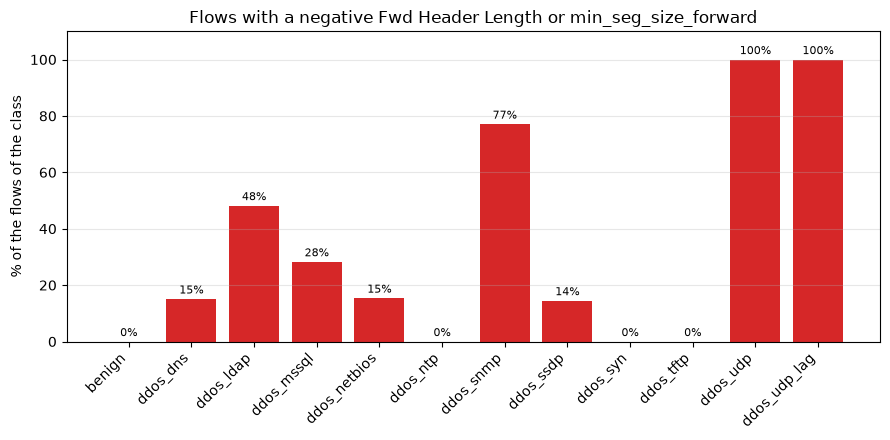

In [46]:
per_class = pd.DataFrame({
    "flows": df["label"].value_counts(),
    "affected": df.loc[bad, "label"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
per_class["% of the class"] = (100 * per_class["affected"] / per_class["flows"]).round(1)
per_class["% of the affected rows"] = (100 * per_class["affected"] / bad.sum()).round(2)
per_class["flows left if the rows were dropped"] = per_class["flows"] - per_class["affected"]
display(per_class)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(per_class.index, per_class["% of the class"],
              color=[BENIGN_COLOR if l == "benign" else ATTACK_COLOR for l in per_class.index])
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in per_class["% of the class"]], padding=2, fontsize=8)
ax.set_ylim(0, 110)
ax.set_ylabel("% of the flows of the class")
ax.set_title("Flows with a negative Fwd Header Length or min_seg_size_forward")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
show_figure(fig, ANALYSIS, "01_negative_header_values_per_class")

The affected rows are far from random:

- **fully affected:** every flow of `ddos_udp_lag` and all but one of `ddos_udp`;
- **largely affected:** 77% of `ddos_snmp` and 48% of `ddos_ldap`;
- **partly affected:** between 14.5% and 28.3% of `ddos_dns`, `ddos_mssql`, `ddos_netbios` and `ddos_ssdp`;
- **not affected:** the TCP classes (`ddos_ntp`, `ddos_syn`, `ddos_tftp`), and benign apart from a single flow.

So the problem is not simply "UDP". The 2,132 benign DNS flows of §4.6 are UDP too, yet only one benign flow is hit: the corruption follows the attack captures, not the protocol.

Where do the values come from? `Fwd Header Length` is a sum over the forward packets of the flow, so dividing it by `Total Fwd Packets` gives the average value recorded per packet.

In [47]:
garbage = df["min_seg_size_forward"].min()            # the most negative value recorded
per_packet = df.loc[fhl_neg, "Fwd Header Length"] / df.loc[fhl_neg, "Total Fwd Packets"]
pattern = pd.Series(np.select([per_packet == -1, per_packet == garbage],
                              ["-1 for every packet", f"{garbage:,} for every packet"],
                              default="mix of the two, or of invalid and valid packets"),
                    index=per_packet.index)
display(pattern.value_counts().rename_axis("Fwd Header Length / Total Fwd Packets").to_frame("flows"))
display(df.loc[mss_neg, "min_seg_size_forward"].value_counts()
        .rename_axis("negative min_seg_size_forward").to_frame("flows"))

,flows
Fwd Header Length / Total Fwd Packets,
-1 for every packet,21061
"-1,062,718,975 for every packet",2159
"mix of the two, or of invalid and valid packets",361


,flows
negative min_seg_size_forward,
-1,21068
-1062718975,2519


The values are not random overflows:

- **21,061 rows:** `Fwd Header Length` is exactly minus the number of forward packets, so −1 was recorded as the header length of every packet and then summed;
- **2,159 rows:** every packet contributed −1,062,718,975. The same number is the `min_seg_size_forward` of 2,519 rows and appears in the single negative `Bwd Header Length` (§7.5);
- **the remaining 361 rows** mix the two values, or mix them with valid packets.

Accordingly, `min_seg_size_forward`, the minimum over the same packets, takes only the values −1 and −1,062,718,975. In short, for some UDP packets the extractor recorded an invalid header length (−1 or a constant garbage number), which then propagated into the flow totals.

### 7.4 Drop the rows or drop the columns?

The table of §7.3 already shows what dropping the 23,587 rows would cost. The alternative, keeping the two columns, has a different cost: a negative value would work as an almost perfect "this is an attack" rule. How good would that rule be?

In [48]:
is_attack = df["label"] != "benign"
print(f"Rule 'negative Fwd Header Length or min_seg_size_forward => attack':")
print(f"  precision {is_attack[bad].mean():.4%}  ({(~is_attack[bad]).sum()} benign flow among {bad.sum():,})")
print(f"  it fires on {bad[is_attack].mean():.1%} of the attack flows ({bad[is_attack].sum():,} of {is_attack.sum():,})")

Rule 'negative Fwd Header Length or min_seg_size_forward => attack':
  precision 99.9958%  (1 benign flow among 23,587)
  it fires on 40.3% of the attack flows (23,586 of 58,581)


Both options have a cost, but the costs are not comparable:

- **dropping the 23,587 rows** would remove 36.7% of the dataset and practically delete two classes: `ddos_udp_lag` would keep 0 flows and `ddos_udp` 1. Most of `ddos_snmp` would go too (1,369 left of 5,984);
- **keeping the columns** would hand the model a shortcut. A negative value means "attack" with 99.996% precision (1 benign flow among 23,587), and the rule fires on 40.3% of all attack flows. A model would learn the extractor's bug and would fail on data where the bug is absent or different.

Dropping the two columns sacrifices the forward header length, information that no other column carries (§7.5), but keeps all the flows and removes the shortcut. This is why both columns are removed (CORR, §8).

### 7.5 `Bwd Header Length`, and how these values distort §3 and §5

`Bwd Header Length` (the backward counterpart of `Fwd Header Length`) has a single negative value.

In [49]:
bhl_neg = df["Bwd Header Length"] < 0
display(df.loc[bhl_neg, ["label", "Protocol", "Total Fwd Packets", "Total Backward Packets",
                         "Fwd Header Length", "Bwd Header Length", "min_seg_size_forward"]])
print("Bwd Header Length / Total Backward Packets =",
      f"{(df.loc[bhl_neg, 'Bwd Header Length'] / df.loc[bhl_neg, 'Total Backward Packets']).iloc[0]:,.0f}")

,label,Protocol,Total Fwd Packets,Total Backward Packets,Fwd Header Length,Bwd Header Length,min_seg_size_forward
21205,benign,17,2,2,28,-2125437950,14


Bwd Header Length / Total Backward Packets = -1,062,718,975


A single flow, benign and UDP, with 2 backward packets. The value is exactly 2 × −1,062,718,975, the same invalid per-packet value as in §7.3. Its forward columns are valid (28 and 14), so this row is not among the 23,587 of §7.3. In total, two benign flows contain an invalid value: one in the forward columns (§7.3) and this one. Since the rest of the column is clean, the cleaning of §9 drops this row and keeps the column.

Sections 3–6 ran on the raw values. The statistics of §3.12 show the effect directly (the mean of `Fwd Header Length` is −1.6·10⁹ bytes). For the correlations of §5, the next cell recomputes, for each column with negative values, its highest |correlation| with the other behaviour features, first on all the rows (as in §5) and then only on the rows where the column is not negative.

In [50]:
ID_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp",
           "Source Port", "Destination Port", "Protocol"]           # as in §5
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
behaviour = df.select_dtypes(include="number").drop(columns=const_cols + ID_COLS, errors="ignore")

rows = []
for col in ["Fwd Header Length", "min_seg_size_forward", "Bwd Header Length"]:
    others = behaviour.drop(columns=[col, "Fwd Header Length.1"], errors="ignore")
    valid = behaviour[col] >= 0
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore")    # columns that are constant on the subset give NaN
        r_all = others.corrwith(behaviour[col]).abs()
        r_valid = others[valid].corrwith(behaviour.loc[valid, col]).abs()
    rows.append({"column": col,
                 "best |r|, all rows (§5)": f"{r_all.max():.3f}  ({r_all.idxmax()})",
                 "valid rows": f"{valid.sum():,}",
                 "best |r|, valid rows only": f"{r_valid.max():.3f}  ({r_valid.idxmax()})"})
distortion = pd.DataFrame(rows).set_index("column")
display(distortion)

,"best |r|, all rows (§5)",valid rows,"best |r|, valid rows only"
column,,,
Fwd Header Length,0.484 (min_seg_size_forward),"40,658",0.383 (act_data_pkt_fwd)
min_seg_size_forward,0.484 (Fwd Header Length),"40,652",0.236 (Average Packet Size)
Bwd Header Length,0.013 (Inbound),"64,238",0.993 (Total Backward Packets)


The corrupted values distort §5 in two different ways:

- **`Fwd Header Length` and `min_seg_size_forward`**: on all the rows they correlate mostly with each other (0.484), because their invalid values occur in the same flows. On the valid rows their best correlations drop to 0.383 and 0.236. They are not redundant with any other column, so §5 missed nothing about them, and removing them does lose information that exists nowhere else.
- **`Bwd Header Length`** is the striking case. A single value of −2.1·10⁹ makes it look unrelated to everything (best |r| 0.013, with `Inbound`). On the other 64,238 rows its correlation with `Total Backward Packets` is 0.993, above the 0.95 threshold of §5. The column is redundant, the raw-data analysis could not see it, and it is not in the removal list (§8.4).

The statistics of §3.12 suffer in the same way: the means and standard deviations of the corrupted columns are meaningless, and so would be any standardisation computed before cleaning.

### 7.6 `Init_Win_bytes_forward` and `Init_Win_bytes_backward` = −1

The initial TCP window of each direction. CICFlowMeter writes −1 when there is no value to report.

In [51]:
for c in ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]:
    minus_one = df[c] == -1
    print(f"{c} = -1 in {minus_one.sum():,} flows ({minus_one.mean():.1%}); "
          f"other negative values: {((df[c] < 0) & ~minus_one).sum()}")
    display(pd.crosstab(TRANSPORT.rename("transport"), minus_one.rename(f"{c} = -1")))

tcp_no_bwd_win = (TRANSPORT == "TCP") & (df["Init_Win_bytes_backward"] == -1)
print(f"TCP flows with Init_Win_bytes_backward = -1: {tcp_no_bwd_win.sum():,}, "
      f"of which with no backward packets: {(df.loc[tcp_no_bwd_win, 'Total Backward Packets'] == 0).sum():,}")

Init_Win_bytes_forward = -1 in 48,928 flows (76.2%); other negative values: 0


Init_Win_bytes_forward = -1,False,True
transport,,
TCP,15311,0
UDP,0,48870
other,0,58


Init_Win_bytes_backward = -1 in 58,018 flows (90.3%); other negative values: 0


Init_Win_bytes_backward = -1,False,True
transport,,
TCP,6221,9090
UDP,0,48870
other,0,58


TCP flows with Init_Win_bytes_backward = -1: 9,090, of which with no backward packets: 9,090


`Init_Win_bytes_forward` is −1 in exactly the 48,870 UDP flows and the 58 protocol-0 flows, and never in a TCP flow. `Init_Win_bytes_backward` is −1 in the same flows plus 9,090 TCP flows, all of which have no backward packet.

So −1 means "no TCP window to report": either the protocol has none, or the other side never answered. It is a legitimate value and is kept. Note that it is a category hidden in a numeric column: tree-based models handle it naturally, while models based on distances or linear combinations will treat it as "one byte less than 0".

### 7.7 `SimillarHTTP`

According to the description of the dataset, this column measures how similar the flow is to HTTP. In practice it contains `0` or, for a few flows, the URL of an HTTP request. With the default reading options pandas guesses the type of each column on blocks of rows, so this column can come out with mixed types; `low_memory=False`, used by `read_raw_csv()` and `load_dataset()`, makes it read the whole column at once.

In [52]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    default_read = pd.read_csv(DATA_CSV)                 # default options (low_memory=True)
for w in caught:
    print(f"{w.category.__name__}: {w.message}")
default_read.columns = default_read.columns.str.strip()


def python_types(s):
    return s.map(lambda v: type(v).__name__).value_counts().to_dict()


display(pd.DataFrame({
    "pandas dtype": [str(default_read["SimillarHTTP"].dtype), str(df["SimillarHTTP"].dtype)],
    "Python types of the values": [python_types(default_read["SimillarHTTP"]),
                                   python_types(df["SimillarHTTP"])],
}, index=["read_csv(path)  (default)", "read_csv(path, low_memory=False)"]))
del default_read

,pandas dtype,Python types of the values
read_csv(path) (default),object,"{'str': 40960, 'int': 23279}"
"read_csv(path, low_memory=False)",str,{'str': 64239}


With the default options pandas reads the file in blocks and infers each block's type separately. The blocks that contain only `0` become integers and the others text, so the column ends up with 23,279 integers and 40,960 strings, and pandas emits the `DtypeWarning`. With `low_memory=False`, the option used throughout this notebook, all 64,239 values are strings: here the column never has mixed types, and the conversion with `astype(str)` in the cleaning of §9 is a safety measure rather than a necessity. The next cell looks at the content: how many values are `0`, in which classes the other values appear, and which URLs are the most frequent.

In [53]:
is_zero = df["SimillarHTTP"].astype(str).str.strip() == "0"
print(f"'0': {is_zero.sum():,} flows ({is_zero.mean():.2%}); any other value: {(~is_zero).sum()} flows, "
      f"{df.loc[~is_zero, 'SimillarHTTP'].nunique()} distinct strings")
http_per_class = pd.DataFrame({
    "flows": df["label"].value_counts(),
    "with an HTTP request": df.loc[~is_zero, "label"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
http_per_class["%"] = (100 * http_per_class["with an HTTP request"] / http_per_class["flows"]).round(1)
display(http_per_class)
display(df.loc[~is_zero, "SimillarHTTP"].value_counts()
        .sort_index().sort_values(ascending=False, kind="stable")      # ties in alphabetical order
        .head(7).to_frame("flows"))

'0': 63,761 flows (99.26%); any other value: 478 flows, 186 distinct strings


,flows,with an HTTP request,%
label,,,
benign,5658,282,5.0
ddos_dns,5369,18,0.3
ddos_ldap,5928,0,0.0
ddos_mssql,5911,1,0.0
ddos_netbios,5830,0,0.0
ddos_ntp,986,177,18.0
ddos_snmp,5984,0,0.0
ddos_ssdp,5970,0,0.0
ddos_syn,5480,0,0.0


,flows
SimillarHTTP,
205.174.165.72/c.php,151
ocsp.digicert.com/,25
ocsp.pki.goog/GTSGIAG3,24
205.174.165.72/c.php?ip=10.148.118.37,12
205.174.165.72null,8
detectportal.firefox.com/success.txt,6
drmokhberi.ca/favicon.ico,6


`SimillarHTTP` is `0` in 99.26% of the flows. The other 478 flows contain one of 186 URLs: certificate checks (OCSP), Firefox's connectivity check and, most often, requests to `205.174.165.72/c.php`. These strings are specific to the experiment and useless as such, but the presence of a request is informative: it occurs in 282 benign flows (5.0%) and 177 `ddos_ntp` flows (18.0%), and almost nowhere else. This is why the cleaning keeps the column as a 0/1 indicator (§9). That 18% of a class named after an NTP attack contains HTTP requests is another sign, after §4.4, that `ddos_ntp` is not NTP traffic.

### 7.8 `Source Port`

`Source Port` is still in the dataset: whether to remove it is discussed in §8.5. §6.2 showed the ports graphically; the table below summarises, for each class, the number of distinct values, the most frequent port, the share of well-known ports (< 1,024) and the share of ports ≥ 32,768, where the ephemeral range used by Linux starts (Windows and the IANA dynamic range start at 49,152). `Destination Port`, which is kept, is shown for comparison.

In [54]:
def port_profile(s):
    vc = s.value_counts().sort_index().sort_values(ascending=False, kind="stable")   # ties: lowest port first
    return {"distinct": s.nunique(),
            "most frequent (share)": f"{vc.index[0]} ({vc.iloc[0] / len(s):.0%})",
            "% < 1024": round(100 * (s < 1024).mean(), 1),
            "% >= 32768": round(100 * (s >= 32768).mean(), 1)}

profile = pd.concat({col: pd.DataFrame({lab: port_profile(df.loc[df["label"] == lab, col])
                                        for lab in LABELS}).T
                     for col in ["Source Port", "Destination Port"]}, axis=1)
print(f"Distinct values in the whole dataset: Source Port {df['Source Port'].nunique():,}, "
      f"Destination Port {df['Destination Port'].nunique():,}")
display(profile)
same_port = (df["Source Port"] == df["Destination Port"]).groupby(df["label"]).mean().mul(100).round(1)
print("Flows with Source Port = Destination Port, classes above 1%:",
      {k: f"{v}%" for k, v in same_port[same_port > 1].items()})

Distinct values in the whole dataset: Source Port 22,994, Destination Port 34,733


Source Port                                           Destination Port                                          
                distinct most frequent (share) % < 1024 % >= 32768         distinct most frequent (share) % < 1024 % >= 32768
benign              2725             443 (13%)     19.6       80.2              893              53 (38%)     81.0       18.7
ddos_dns             553             634 (77%)     91.1        8.2             4879               80 (1%)      2.6       50.3
ddos_ldap            368             900 (94%)    100.0        0.0             5693              659 (0%)      1.9       50.0
ddos_mssql           521             900 (18%)     99.8        0.1             5619             9077 (0%)      1.6       50.6
ddos_netbios        4901           61850 (16%)      0.0       99.8             5528             3641 (0%)      1.6       49.8
ddos_ntp             349              80 (25%)     32.5       49.9              341              80 (50%)     64.3       24.5
ddos_snmp            511             648 (17%)    100.0        0.0             5704            11565 (0%)      2.0       49.1
ddos_ssdp            515             672 (17%)     99.9        0.1             5686             2489 (0%)      1.4       50.0
ddos_syn            5274            62555 (0%)      1.5       80.4             4927             7512 (0%)      1.5       50.0
ddos_tftp           5159              681 (0%)      1.6       82.9             4797            45268 (0%)      1.6       51.1
ddos_udp            5118            44617 (0%)      0.1       99.8             2171             1156 (0%)      0.1       51.9
ddos_udp_lag        5236            34892 (0%)      0.0       99.9             2221            36506 (0%)      0.0       51.4

Flows with Source Port = Destination Port, classes above 1%: {'ddos_syn': '39.3%', 'ddos_tftp': '34.1%'}


The table quantifies what §6.2 showed:

- **random source ports:** `ddos_netbios`, `ddos_syn`, `ddos_tftp`, `ddos_udp` and `ddos_udp_lag` have about 5,000 distinct source ports each, no port above 1% of their flows (except 61850 for `ddos_netbios`, 16%), and 80–100% of them in the ephemeral range;
- **fixed low source ports:** `ddos_dns`, `ddos_ldap`, `ddos_mssql`, `ddos_snmp` and `ddos_ssdp` send almost only from privileged ports (91–100% below 1,024). They use a few hundred values, and the most frequent covers between 17% and 94% of the flows;
- **benign:** the source port is below 1,024 in 19.6% of the flows (replies from servers, 443 in 13%) and ephemeral otherwise.

`ddos_syn` and `ddos_tftp` have another peculiarity: in more than a third of their flows the source port equals the destination port. The destination port has the opposite profile: random for every attack class except `ddos_ntp` (about half of the flows at 32,768 or above, i.e. uniform over the whole range), and a service port for 81% of the benign flows.

Do the reflection attacks use the standard port of the service they are named after, on either side of the flow?

In [55]:
SERVICE_PORTS = {"ddos_dns": [53], "ddos_ldap": [389], "ddos_mssql": [1434],
                 "ddos_netbios": [137, 138, 139], "ddos_ntp": [123], "ddos_snmp": [161, 162],
                 "ddos_ssdp": [1900], "ddos_tftp": [69]}
service_use = pd.DataFrame([{
    "class": lab,
    "service port(s)": ", ".join(map(str, ports)),
    "flows using it": int((df.loc[df["label"] == lab, "Source Port"].isin(ports)
                           | df.loc[df["label"] == lab, "Destination Port"].isin(ports)).sum()),
    "flows": int((df["label"] == lab).sum()),
    "transport": ", ".join(f"{p} {n}" for p, n in TRANSPORT[df["label"] == lab].value_counts().items()),
} for lab, ports in SERVICE_PORTS.items()]).set_index("class")
display(service_use)

,service port(s),flows using it,flows,transport
class,,,,
ddos_dns,53,0,5369,"UDP 5223, TCP 142, other 4"
ddos_ldap,389,1,5928,"UDP 5925, TCP 2, other 1"
ddos_mssql,1434,0,5911,"UDP 5909, other 1, TCP 1"
ddos_netbios,"137, 138, 139",0,5830,"UDP 5829, other 1"
ddos_ntp,123,0,986,"TCP 973, other 7, UDP 6"
ddos_snmp,"161, 162",0,5984,UDP 5984
ddos_ssdp,1900,0,5970,"UDP 5966, TCP 3, other 1"
ddos_tftp,69,0,5261,"TCP 5257, UDP 3, other 1"


No flow of any reflection class uses the port of its service, on either side; a single `ddos_ldap` flow out of 5,928 is the only exception. The ports in the data are therefore choices of the attack tools in this testbed, not protocol semantics. For `ddos_ntp` and `ddos_tftp` the mismatch goes further: they are TCP flows (973 of 986 and 5,257 of 5,261) and never touch ports 123 or 69, so their content does not match their name (§4.4, §7.7).

## 8. Why each column is removed

The cleaning of §9 removes the columns listed below. Each one has a tag with the reason:

- **ESCL** — identifiers (IPs, flow ID, time): they say *who* and *when*, not *how* the traffic behaves, and a model would learn the addresses of the experiment instead of the attacks;
- **RID** — redundant: the information is already in another column;
- **ELIM** — not informative: constant, or a copy of another column;
- **CORR** — corrupted: impossible negative values (§7.2–§7.4).

This section defines the list, checks the exact formulas behind the RID columns, builds a table that links every removed column to its evidence in this notebook, and finally checks whether the analyses contradict the list or suggest removals that are not in it.

### 8.1 The columns to remove

The list, with the tag of each column. `Source Port` is commented out: whether to remove it is discussed in §8.5. The cell also defines the two columns where −1 is a legitimate value (§7.6) and `show_left()`, which displays tables of sentences with left-aligned cells.

In [56]:
COLUMNS_TO_REMOVE = {
    "Flow ID":                        "ESCL",
    "Destination IP":                 "ESCL",
    "Source IP":                      "ESCL",
    "Timestamp":                      "ESCL",
    # "Source Port":                  "ESCL",      # still to be decided (§8.5): uncomment to remove it
    "Total Length of Bwd Packets":    "RID",
    "Fwd Packet Length Min":          "RID",
    "Fwd Packet Length Mean":         "RID",
    "Min Packet Length":              "RID",
    "Packet Length Mean":             "RID",
    "Packet Length Std":              "RID",
    "Packet Length Variance":         "RID",
    "Average Packet Size":            "RID",
    "Avg Fwd Segment Size":           "RID",
    "Avg Bwd Segment Size":           "RID",
    "Fwd Packets/s":                  "RID",
    "Fwd IAT Total":                  "RID",
    "Fwd IAT Mean":                   "RID",
    "Fwd IAT Std":                    "RID",
    "Fwd IAT Max":                    "RID",
    "Fwd IAT Min":                    "RID",
    "Bwd IAT Std":                    "RID",
    "Idle Max":                       "RID",
    "Idle Min":                       "RID",
    "FIN Flag Count":                 "ELIM",
    "RST Flag Count":                 "ELIM",
    "PSH Flag Count":                 "ELIM",
    "ECE Flag Count":                 "ELIM",
    "Bwd PSH Flags":                  "ELIM",
    "Fwd URG Flags":                  "ELIM",
    "Bwd URG Flags":                  "ELIM",
    "Fwd Header Length.1":            "ELIM",
    "Fwd Avg Bytes/Bulk":             "ELIM",
    "Fwd Avg Packets/Bulk":           "ELIM",
    "Fwd Avg Bulk Rate":              "ELIM",
    "Bwd Avg Bytes/Bulk":             "ELIM",
    "Bwd Avg Packets/Bulk":           "ELIM",
    "Bwd Avg Bulk Rate":              "ELIM",
    "Subflow Fwd Packets":            "ELIM",
    "Subflow Fwd Bytes":              "RID",
    "Subflow Bwd Packets":            "ELIM",
    "Subflow Bwd Bytes":              "RID",
    "act_data_pkt_fwd":               "RID",
    "Fwd Header Length":              "CORR",
    "min_seg_size_forward":           "CORR",
}

REMOVE = list(COLUMNS_TO_REMOVE)       # column names
TAGS = COLUMNS_TO_REMOVE               # column -> tag

# columns where -1 is a legitimate value: "not available" (§7.6)
MINUS_ONE_ALLOWED = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]


def show_left(table, precision=2):
    """Display a table with left-aligned cells: easier to read when they hold sentences."""
    display(table.style.format(precision=precision)
            .set_properties(**{"text-align": "left"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))


print(f"{len(REMOVE)} columns to remove")
display(pd.Series(TAGS).value_counts().rename_axis("tag").to_frame("columns"))

44 columns to remove


,columns
tag,
RID,22
ELIM,16
ESCL,4
CORR,2


The list has 44 columns: 22 RID, 16 ELIM, 4 ESCL and 2 CORR. `Source Port` is not counted, because its line is commented out (§8.5).

### 8.2 Exact relations between columns

Several RID and ELIM columns are not just correlated with another column: they can be computed from it. The cell checks ten formulas row by row (relative tolerance 10⁻⁶) and tells whether the right-hand side uses only columns that are kept. Two pairs of §5.3 with correlation 1.000 that §5.2 did not report as identical (one column is stored as integers, the other as floats) are included: `Subflow Fwd Bytes` and `Subflow Bwd Bytes`.

In [57]:
THRESHOLD = 0.95                                   # same threshold as §5
df = load_dataset()
kept = [c for c in df.columns if c not in REMOVE]  # 42 features + label

# (removed column, formula, columns used by the formula, value of the formula)
DERIVATIONS = [
    ("Fwd Packet Length Mean", "Total Length of Fwd Packets / Total Fwd Packets",
     ["Total Length of Fwd Packets", "Total Fwd Packets"],
     df["Total Length of Fwd Packets"] / df["Total Fwd Packets"]),
    ("Avg Fwd Segment Size", "Fwd Packet Length Mean",
     ["Fwd Packet Length Mean"], df["Fwd Packet Length Mean"]),
    ("Avg Bwd Segment Size", "Bwd Packet Length Mean",
     ["Bwd Packet Length Mean"], df["Bwd Packet Length Mean"]),
    ("Total Length of Bwd Packets", "Bwd Packet Length Mean × Total Backward Packets",
     ["Bwd Packet Length Mean", "Total Backward Packets"],
     df["Bwd Packet Length Mean"] * df["Total Backward Packets"]),
    ("Subflow Fwd Bytes", "Total Length of Fwd Packets",
     ["Total Length of Fwd Packets"], df["Total Length of Fwd Packets"]),
    ("Subflow Bwd Bytes", "Total Length of Bwd Packets",
     ["Total Length of Bwd Packets"], df["Total Length of Bwd Packets"]),
    ("Fwd Packets/s", "Flow Packets/s − Bwd Packets/s",
     ["Flow Packets/s", "Bwd Packets/s"], df["Flow Packets/s"] - df["Bwd Packets/s"]),
    ("Packet Length Variance", "Packet Length Std²",
     ["Packet Length Std"], df["Packet Length Std"] ** 2),
    ("Fwd IAT Total", "Flow Duration", ["Flow Duration"], df["Flow Duration"]),
    ("Min Packet Length", "Fwd Packet Length Min",
     ["Fwd Packet Length Min"], df["Fwd Packet Length Min"]),
]
derivations = pd.DataFrame([{
    "removed column": col,
    "= formula": formula,
    "% of rows where it holds": round(100 * np.isclose(df[col], value, rtol=1e-6, atol=1e-9).mean(), 2),
    "formula uses only kept columns": all(c in kept for c in inputs),
} for col, formula, inputs, value in DERIVATIONS]).set_index("removed column")
show_left(derivations)

,= formula,% of rows where it holds,formula uses only kept columns
removed column,,,
Fwd Packet Length Mean,Total Length of Fwd Packets / Total Fwd Packets,100.00,True
Avg Fwd Segment Size,Fwd Packet Length Mean,100.00,False
Avg Bwd Segment Size,Bwd Packet Length Mean,100.00,True
Total Length of Bwd Packets,Bwd Packet Length Mean × Total Backward Packets,100.00,True
Subflow Fwd Bytes,Total Length of Fwd Packets,100.00,True
Subflow Bwd Bytes,Total Length of Bwd Packets,100.00,False
Fwd Packets/s,Flow Packets/s − Bwd Packets/s,100.00,True
Packet Length Variance,Packet Length Std²,100.00,False
Fwd IAT Total,Flow Duration,91.08,True


Eight of the ten formulas hold in every row:

- **computable from kept columns (5):** `Fwd Packet Length Mean`, `Avg Bwd Segment Size`, `Total Length of Bwd Packets`, `Subflow Fwd Bytes` and `Fwd Packets/s` can be recomputed exactly from the cleaned dataset;
- **based on another removed column (3):** `Avg Fwd Segment Size` = `Fwd Packet Length Mean` and `Subflow Bwd Bytes` = `Total Length of Bwd Packets`, both recomputable in turn. The base of `Packet Length Variance` = `Packet Length Std`² is removed too (§8.4).

The last two relations are only approximate: `Fwd IAT Total` equals `Flow Duration` in 91% of the rows, and `Min Packet Length` equals `Fwd Packet Length Min` in 99.94%. Both pairs have correlation 1.000 (§5.3).

### 8.3 Evidence for every removed column

For each column of the list the cell collects, in this order: identifier evidence (ESCL), constancy, identical columns and exact formulas (from §8.2, only those that hold in every row). When the column cannot be recomputed exactly from kept columns, it adds the highest |correlation| with a **kept** column, because what matters is that the information survives somewhere in the cleaned dataset; for a column with impossible values the correlation is computed on the valid rows only (§7.5). If nothing stronger is found, it reports whether the column is almost constant (one value in at least 99% of the rows). Last come the impossible negative values (CORR). The code does not depend on the current list: if the list of §8.1 changes, rerunning the notebook updates the table. The last column gives the sections where the evidence appears.

In [58]:
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
ID_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp",
           "Source Port", "Destination Port", "Protocol"]            # as in §5
behaviour = df.select_dtypes(include="number").drop(columns=const_cols + ID_COLS, errors="ignore")
abs_corr = behaviour.corr().abs()
kept_behaviour = [c for c in behaviour.columns if c in kept]
exact = derivations[derivations["% of rows where it holds"] == 100]

cols = list(behaviour.columns)                     # pairs that §5.2 (Series.equals) reports
found_by_equals = {frozenset((a, b)) for i, a in enumerate(cols) for b in cols[i + 1:]
                   if behaviour[a].equals(behaviour[b])}

def same_values(a, b):
    """Same numbers in every row, whatever the storage type (int or float)."""
    return np.array_equal(df[a].to_numpy(dtype=float), df[b].to_numpy(dtype=float))

def top_share(col):
    """Most frequent value of a column and its share (SimillarHTTP counted as 0/1, as after cleaning)."""
    values = df[col] if col != "SimillarHTTP" else (df[col].astype(str).str.strip() != "0").astype(int)
    shares = values.value_counts(normalize=True)
    return shares.index[0], shares.iloc[0]

def best_kept_partner(col):
    """Kept column with the highest |r|; computed on the valid rows if col has negative values."""
    partners = [c for c in kept_behaviour if c != col]
    if (df[col] < 0).any():
        valid = df[col] >= 0
        with np.errstate(all="ignore"), warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = behaviour.loc[valid, partners].corrwith(behaviour.loc[valid, col]).abs()
        return r.idxmax(), r.max(), ", valid rows"
    r = abs_corr.loc[col, partners]
    return r.idxmax(), r.max(), ""

bad = (df["Fwd Header Length"] < 0) | (df["min_seg_size_forward"] < 0)
src_ips = df.groupby("label")["Source IP"].nunique()
dst_ips = df.groupby("label")["Destination IP"].nunique()
windows = df.groupby("label")["Timestamp"].agg(lambda s: (s.max() - s.min()).total_seconds())
attack_windows = windows.drop("benign")
IDENTIFIERS = {
    "Flow ID": (f"identifier: the string 'source IP-destination IP-source port-destination port-"
                f"protocol' (§3.2), i.e. five other columns pasted together; "
                f"{df['Flow ID'].nunique():,} distinct values", "§3.2, §3.4"),
    "Source IP": (f"identifier: {df['Source IP'].value_counts().index[0]} sends "
                  f"{df['Source IP'].value_counts(normalize=True).iloc[0]:.1%} of the flows; "
                  f"{src_ips.drop('benign').min()}-{src_ips.drop('benign').max()} source IPs per attack "
                  f"class, {src_ips['benign']} for benign", "§4.3"),
    "Destination IP": (f"identifier: {df['Destination IP'].value_counts().index[0]} receives "
                       f"{df['Destination IP'].value_counts(normalize=True).iloc[0]:.1%} of the flows; "
                       f"{dst_ips.drop('benign').min()}-{dst_ips.drop('benign').max()} destination IPs "
                       f"per attack class, {dst_ips['benign']} for benign", "§4.3"),
    "Timestamp": (f"identifier: every attack lies in its own time window, from "
                  f"{attack_windows.min():.1f} s ({attack_windows.idxmin()}) to "
                  f"{attack_windows.max() / 60:.0f} min ({attack_windows.idxmax()}); the time alone "
                  f"would give the class away", "§4.5, §7.1"),
    "Source Port": (f"identifier-like: {df['Source Port'].nunique():,} distinct values, random in the "
                    f"floods and fixed by the attack tools in the reflection classes", "§6.2, §7.8, §8.5"),
    "Destination Port": (f"identifier-like: {df['Destination Port'].nunique():,} distinct values, random "
                         f"in every attack class except ddos_ntp", "§6.2, §7.8, §8.5"),
}

rows = []
for col in REMOVE:
    evidence, sections = [], []
    if col in IDENTIFIERS:
        evidence.append(IDENTIFIERS[col][0])
        sections.append(IDENTIFIERS[col][1])
    if col in const_cols:
        evidence.append(f"constant (always {df[col].iloc[0]})")
        sections.append("§3.7, §5.1")
    copies = []
    if col in behaviour.columns:
        for other in behaviour.columns:
            if other != col and same_values(col, other):
                copies.append(other)
                status = "kept" if other in kept else "removed"
                evidence.append(f"identical to {other} ({status})")
                sections.append("§5.2" if frozenset((col, other)) in found_by_equals else "§8.2")
    exact_with_kept = any(c in kept for c in copies)
    if col in exact.index and exact.loc[col, "= formula"] not in copies:
        uses_kept = exact.loc[col, "formula uses only kept columns"]
        exact_with_kept = exact_with_kept or uses_kept
        evidence.append(f"= {exact.loc[col, '= formula']}"
                        + (" (all kept)" if uses_kept else ""))
        sections.append("§8.2")
    has_negative = col in behaviour.columns and bool((df[col] < 0).any())
    copy_of_corrupted = any(TAGS.get(o) == "CORR" for o in copies)
    strong = exact_with_kept or copy_of_corrupted
    if (col in behaviour.columns and col not in const_cols and TAGS.get(col) in ("RID", "ELIM")
            and not strong):
        partner, r, where = best_kept_partner(col)
        if r > THRESHOLD:
            strong = True
            evidence.append(f"|r| = {r:.3f} with {partner} (kept{where})")
        else:
            evidence.append(f"no kept column with |r| > {THRESHOLD} (best: {partner}, {r:.3f}{where})")
        if not where:                       # valid-rows correlations are covered by §7.2-§7.5 below
            sections.append("§5.3")
    if (col in behaviour.columns or col == "SimillarHTTP") and col not in const_cols and not strong:
        value, share = top_share(col)
        if share >= 0.99:
            evidence.append(f"almost constant: {share:.2%} of the rows are {value}")
            sections.append("§8.3")
    if has_negative:
        n_neg = int((df[col] < 0).sum())
        n_benign = int((df.loc[df[col] < 0, "label"] == "benign").sum())
        evidence.append(f"{n_neg:,} impossible negative value{'s' if n_neg != 1 else ''} "
                        f"(min {df[col].min():,}); benign flows among them: {n_benign}")
        sections.append("§7.2-§7.5")
    refs = dict.fromkeys(", ".join(sections).split(", "))           # unique, in order
    refs = sorted(refs, key=lambda s: [int(n) for n in re.findall(r"\d+", s)])
    rows.append({"column": col, "tag": TAGS.get(col, "?"),
                 "evidence": "; ".join(evidence) or "-", "sections": ", ".join(refs)})

removed_table = pd.DataFrame(rows).set_index("column")
show_left(removed_table)

,tag,evidence,sections
column,,,
Flow ID,ESCL,"identifier: the string 'source IP-destination IP-source port-destination port-protocol' (§3.2), i.e. five other columns pasted together; 60,958 distinct values","§3.2, §3.4"
Destination IP,ESCL,"identifier: 192.168.50.1 receives 90.3% of the flows; 1-2 destination IPs per attack class, 244 for benign",§4.3
Source IP,ESCL,"identifier: 172.16.0.5 sends 90.3% of the flows; 1-2 source IPs per attack class, 215 for benign",§4.3
Timestamp,ESCL,"identifier: every attack lies in its own time window, from 0.6 s (ddos_tftp) to 22 min (ddos_ntp); the time alone would give the class away","§4.5, §7.1"
Total Length of Bwd Packets,RID,identical to Subflow Bwd Bytes (removed); = Bwd Packet Length Mean × Total Backward Packets (all kept),§8.2
Fwd Packet Length Min,RID,|r| = 0.961 with Fwd Packet Length Max (kept),§5.3
Fwd Packet Length Mean,RID,= Total Length of Fwd Packets / Total Fwd Packets (all kept),§8.2
Min Packet Length,RID,|r| = 0.961 with Fwd Packet Length Max (kept),§5.3
Packet Length Mean,RID,|r| = 0.970 with Fwd Packet Length Max (kept),§5.3


Every one of the 44 columns has at least one piece of supporting evidence:

- **ESCL (4):** identifiers whose values would reveal the class (§4.3, §4.5);
- **ELIM (16):** 12 constant columns and 4 exact copies (`RST Flag Count`, `Subflow Fwd Packets`, `Subflow Bwd Packets`, `Fwd Header Length.1`);
- **RID (22):** 21 are either computable from kept columns or correlated above 0.95 with a kept column. The exception is `Packet Length Variance` (§8.4);
- **CORR (2):** invalid values in 23,581 and 23,587 flows, only one of them benign (§7.3).

Two details matter when this table is used in the report. `Total Length of Bwd Packets` and `Subflow Bwd Bytes` are identical and both removed, yet nothing is lost: the information can be recomputed exactly as `Bwd Packet Length Mean × Total Backward Packets`. And the identity of the two `Subflow … Bytes` columns with the byte totals appears only in §8.2, because §5.2 compares data types as well as values.

### 8.4 Do the analyses agree with the list?

Four checks, in both directions:

1. removed RID/ELIM columns that are **not** supported by the evidence of §5, §7.5 and §8.2 (not constant, no identical kept column, no exact formula on kept columns, no kept column above the threshold, and, for ELIM, not almost constant);
2. kept columns that are constant, identical to another kept column, or correlated above the threshold with another kept column — on the raw data, as in §5, and on the rows without negative values;
3. kept columns that are *almost* constant (one value in at least 99% of the rows), with the classes in which their rare values appear;
4. the ELIM tag: every ELIM column should be constant, almost constant or a copy of another column.

In [59]:
# 1. removed RID/ELIM columns without supporting evidence
unsupported = []
for col in REMOVE:
    if TAGS.get(col) not in ("RID", "ELIM") or col in const_cols or col not in behaviour.columns:
        continue
    identical_kept = any(same_values(col, k) for k in kept_behaviour)
    copy_of_corrupted = any(same_values(col, o) for o in REMOVE
                            if TAGS.get(o) == "CORR" and o != col and o in behaviour.columns)
    formula_kept = col in exact.index and exact.loc[col, "formula uses only kept columns"]
    partner, r, where = best_kept_partner(col)
    almost_constant = TAGS[col] == "ELIM" and top_share(col)[1] >= 0.99
    if not (identical_kept or copy_of_corrupted or formula_kept or r > THRESHOLD or almost_constant):
        unsupported.append({"column": col, "tag": TAGS[col],
                            "best kept partner": f"{partner} ({r:.3f}{where})"})
print("1. Removed RID/ELIM columns without supporting evidence:")
display(pd.DataFrame(unsupported).set_index("column") if unsupported else "none")

# 2. kept columns: constant, identical or highly correlated
kept_const = [c for c in kept if c in const_cols]
kept_identical = [(a, b) for i, a in enumerate(kept_behaviour) for b in kept_behaviour[i + 1:]
                  if same_values(a, b)]


def pairs_above(frame, threshold):
    c = frame.corr().abs()
    up = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().dropna()
    return up[up > threshold].sort_values(ascending=False).round(3)


no_negative = (df[kept_behaviour].drop(columns=MINUS_ONE_ALLOWED, errors="ignore")
               >= 0).all(axis=1)
print(f"\n2. Kept columns - constant: {kept_const or 'none'}; identical pairs: {kept_identical or 'none'}")
print(f"   Pairs of kept columns with |r| > {THRESHOLD}, all rows (as in §5):",
      pairs_above(df[kept_behaviour], THRESHOLD).to_dict() or "none")
print(f"   ... on the {no_negative.sum():,} rows without negative values "
      f"(Init_Win_bytes = -1 allowed):", pairs_above(df.loc[no_negative, kept_behaviour], THRESHOLD).to_dict() or "none")

# 3. almost constant kept columns
near = []
for c in [k for k in kept if k != "label" and (k in behaviour.columns or k == "SimillarHTTP")]:
    value, share = top_share(c)
    if share >= 0.99:
        values = df[c] if c != "SimillarHTTP" else (df[c].astype(str).str.strip() != "0").astype(int)
        rare = df.loc[values != value, "label"].value_counts()
        near.append({"column": c, "most frequent value": value,
                     "share": f"{share:.2%}", "other values": int((values != value).sum()),
                     "classes of the other values": ", ".join(f"{k} {v}" for k, v in rare.head(4).items())})
print("\n3. Kept columns with one value in at least 99% of the rows:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(near).set_index("column"))

# 4. ELIM columns: constant or copies?
elim = [c for c in REMOVE if TAGS.get(c) == "ELIM"]
elim_ok = {c: c in const_cols or top_share(c)[1] >= 0.99
              or any(same_values(c, o) for o in behaviour.columns if o != c) for c in elim}
print(f"\n4. ELIM columns that are constant, almost constant or copies: {sum(elim_ok.values())} of {len(elim)}"
      + ("" if all(elim_ok.values()) else f" - not: {[c for c, ok in elim_ok.items() if not ok]}"))

1. Removed RID/ELIM columns without supporting evidence:


,tag,best kept partner
column,,
Packet Length Variance,RID,Bwd Packet Length Max (0.876)



2. Kept columns - constant: none; identical pairs: none
   Pairs of kept columns with |r| > 0.95, all rows (as in §5): none
   ... on the 64,238 rows without negative values (Init_Win_bytes = -1 allowed): {('Total Backward Packets', 'Bwd Header Length'): 0.993}

3. Kept columns with one value in at least 99% of the rows:


,most frequent value,share,other values,classes of the other values
column,,,,
Fwd PSH Flags,0,99.09%,587,"benign 571, ddos_ntp 9, ddos_dns 5, ddos_ldap 1"
SYN Flag Count,0,99.94%,38,"benign 28, ddos_dns 6, ddos_ssdp 2, ddos_ldap 1"
SimillarHTTP,0,99.26%,478,"benign 282, ddos_ntp 177, ddos_dns 18, ddos_mssql 1"



4. ELIM columns that are constant, almost constant or copies: 16 of 16


The analyses agree with the list, with the exceptions below, left to the authors to decide:

1. **`Packet Length Variance` (RID) is weakly supported.** No kept column has |r| > 0.95 with it (best: `Bwd Packet Length Max`, 0.876). It is exactly the square of `Packet Length Std`, but that column is removed too (|r| = 0.976 with `Bwd Packet Length Std`). The overall spread of packet sizes survives only approximately, through `Fwd Packet Length Std` and `Bwd Packet Length Std`. Removing it is defensible, but the reason is "derived from a removed column", not the 0.95 threshold.
2. **`Bwd Header Length` is redundant but kept.** On the raw data it correlates with nothing (§5). Without its single invalid value, its correlation with `Total Backward Packets` is 0.993, the only pair of kept columns above 0.95. By the criterion applied to the RID columns it would qualify for removal; §9.3 confirms the pair on the cleaned dataset.
3. **`SYN Flag Count` carries almost no information.** It is non-zero in only 38 flows and never in `ddos_syn` (§6.4), which makes it a candidate for removal.

The other checks are clean: no kept column is constant or a copy of another, and all 16 ELIM columns are constant or copies. Besides `SYN Flag Count`, two kept columns are almost constant, `Fwd PSH Flags` (587 non-zero values, mostly benign) and `SimillarHTTP` (478, §7.7). Their rare values are concentrated in a few classes, so they can still be useful.

### 8.5 `Source Port`: arguments for and against removing it

In the list of §8.1 the line of `Source Port` is commented out, so the column is kept for now. The evidence of §6.2, §7.8 and §9.4 points both ways.

**For removing it**

- It is mostly an arbitrary number: 22,994 distinct values. In `ddos_netbios`, `ddos_syn`, `ddos_tftp`, `ddos_udp` and `ddos_udp_lag` it is practically random, and in benign traffic it is usually an ephemeral port chosen by the operating system (80% of the flows at 32,768 or above).
- Where it is not random, it reflects the configuration of the attack tools, not the protocol: 900 for 94% of `ddos_ldap`, 634 for 77% of `ddos_dns`, and no reflection class uses its service port (§7.8). A model could memorise these values as it would memorise the IPs, which is the reasoning behind the ESCL tag, and they would not carry over to other captures.
- A port is a label, not a quantity: 900 and 901 are not "close". Used as a number, it invites splits on arbitrary ranges.

**For keeping it**

- Part of its information is genuine: the share of privileged ports separates the reflection classes (91–100% of flows below 1,024) from the floods (80% or more ephemeral), and in benign traffic a low source port marks a reply from a server (443, 80).
- It keeps flows distinguishable. Without it, 966 more rows of the cleaned dataset would become exact duplicates, and the rows whose features also appear with another label would grow from 92 to 1,032 (§9.4). No model can classify those rows correctly.
- In `ddos_syn` and `ddos_tftp` more than a third of the flows have equal source and destination ports, a pattern visible only if both ports are kept.

**Consistency with `Destination Port`, which is kept.** For the attacks it is just as random (about half of the flows at 32,768 or above, i.e. uniform over the whole range); for benign traffic it carries the service. Whatever is decided for `Source Port`, the same arguments apply to it.

**A middle way**, if the information is wanted without the arbitrary values: replace each port with its range (well-known below 1,024, registered 1,024–49,151, dynamic 49,152 and above), or with a 0/1 "privileged port" flag. This would be a change to the cleaning, and it is not made here.

## 9. Final cleaning

The function `clean_dataset()` applies the decisions of the previous sections to the raw file:

1. it removes the columns of §8.1;
2. it drops the row with the negative `Bwd Header Length` (§7.5);
3. it turns `SimillarHTTP` into a 0/1 column (§7.7);
4. it removes duplicate rows, which could otherwise end up in both the training and the test set.

Its `assert` statements stop the notebook if any missing, infinite, negative (apart from `Init_Win_bytes_* = −1`) or non-numeric value is left. The checks are then repeated one by one in §9.2, so that their results are visible.

### 9.1 The cleaning function

In [60]:
def clean_dataset(raw):
    """Apply all the cleaning decisions to the raw dataset and check the result."""
    ddos = raw.copy()
    ddos.columns = ddos.columns.str.strip()
    if INDEX_COL in ddos.columns:                  # unnamed index column, if any (§2.4)
        ddos = ddos.drop(columns=INDEX_COL)

    # 1. the columns of §8.1 (the warning reveals typos in the list)
    missing = [c for c in REMOVE if c not in ddos.columns]
    if missing:
        print("WARNING - columns not found:", missing)
    ddos = ddos.drop(columns=REMOVE, errors="ignore")

    # 2. the single negative Bwd Header Length (§7.5): that row is dropped
    if "Bwd Header Length" in ddos.columns:
        ddos.loc[ddos["Bwd Header Length"] < 0, "Bwd Header Length"] = np.nan
        ddos = ddos.dropna(subset=["Bwd Header Length"])

    # 3. SimillarHTTP: 1 if the flow contains an HTTP request, 0 otherwise (§7.7)
    ddos["SimillarHTTP"] = (ddos["SimillarHTTP"].astype(str).str.strip() != "0").astype(int)

    # 4. duplicate rows
    ddos = ddos.drop_duplicates().reset_index(drop=True)

    # checks
    numeric = ddos.select_dtypes("number")
    assert ddos.isna().sum().sum() == 0, "There are still missing values"
    assert not np.isinf(numeric).values.any(), "There are infinite values"
    negative = (numeric.drop(columns=MINUS_ONE_ALLOWED, errors="ignore") < 0).sum()
    negative = negative[negative > 0]
    assert negative.empty, f"Unexpected negative values:\n{negative}"
    non_numeric = [c for c in ddos.columns if c != "label" and c not in numeric.columns]
    assert not non_numeric, f"Non-numeric columns: {non_numeric}"
    return ddos


ddos = clean_dataset(read_raw_csv())
print(f"Cleaned dataset: {ddos.shape[0]:,} rows x {ddos.shape[1]} columns "
      f"({ddos.shape[1] - 1} features + label)")

Cleaned dataset: 64,236 rows x 43 columns (42 features + label)


The function ran without errors, so none of its `assert` checks failed: the cleaned dataset has 64,236 rows and 43 columns (42 features and the label). The next cell repeats the checks one by one, so that their results are visible, and compares the class sizes before and after the cleaning.

### 9.2 Checks

In [61]:
before = load_dataset()
numeric = ddos.select_dtypes("number")
# the row with the negative Bwd Header Length is dropped only while that column is kept
n_bhl = int((before["Bwd Header Length"] < 0).sum()) if "Bwd Header Length" not in REMOVE else 0
n_dup_removed = len(before) - n_bhl - len(ddos)
checks = pd.DataFrame([
    ("rows", f"{len(ddos):,}",
     f"{len(before):,} - {n_bhl} (negative Bwd Header Length) - {n_dup_removed} (duplicates)"),
    ("columns", ddos.shape[1], f"{before.shape[1]} - {len(REMOVE)} removed = {before.shape[1] - len(REMOVE)}"),
    ("'Unnamed: 0' among the columns", INDEX_COL in ddos.columns, "must be False"),
    ("columns of the list (§8.1) still present", sum(c in ddos.columns for c in REMOVE), "must be 0"),
    ("missing values (NaN)", int(ddos.isna().sum().sum()), "must be 0"),
    ("infinite values", int(np.isinf(numeric).values.sum()), "must be 0"),
    ("negative values outside Init_Win_bytes_*",
     int((numeric.drop(columns=MINUS_ONE_ALLOWED, errors="ignore") < 0).sum().sum()), "must be 0"),
    ("Init_Win_bytes_forward / _backward = -1 (kept on purpose)",
     " / ".join(f"{(ddos[c] == -1).sum():,}" for c in MINUS_ONE_ALLOWED if c in ddos.columns) or "-",
     "'not available' (§7.6)"),
    ("non-numeric feature columns", [c for c in ddos.columns if c != "label" and c not in numeric.columns],
     "must be empty"),
    ("duplicate rows", int(ddos.duplicated().sum()), "must be 0"),
    ("constant columns", [c for c in ddos.columns if ddos[c].nunique() <= 1], "must be empty"),
    ("values of SimillarHTTP", sorted(ddos["SimillarHTTP"].unique().tolist()), "0/1 (§7.7)"),
    ("Source Port still present", "Source Port" in ddos.columns,
     "commented out in the list (§8.5)" if "Source Port" not in REMOVE else "removed by the list (§8.5)"),
], columns=["check", "result", "expected / note"]).set_index("check")
show_left(checks)

after = ddos["label"].value_counts()
display(pd.DataFrame({"before": before["label"].value_counts(), "after": after})
        .reindex(class_order(before)).assign(removed=lambda t: t["before"] - t["after"]))

,result,expected / note
check,,
rows,"64,236","64,239 - 1 (negative Bwd Header Length) - 2 (duplicates)"
columns,43,87 - 44 removed = 43
'Unnamed: 0' among the columns,False,must be False
columns of the list (§8.1) still present,0,must be 0
missing values (NaN),0,must be 0
infinite values,0,must be 0
negative values outside Init_Win_bytes_*,0,must be 0
Init_Win_bytes_forward / _backward = -1 (kept on purpose),"48,925 / 58,015",'not available' (§7.6)
non-numeric feature columns,[],must be empty


,before,after,removed
label,,,
benign,5658,5657,1
ddos_dns,5369,5367,2
ddos_ldap,5928,5928,0
ddos_mssql,5911,5911,0
ddos_netbios,5830,5830,0
ddos_ntp,986,986,0
ddos_snmp,5984,5984,0
ddos_ssdp,5970,5970,0
ddos_syn,5480,5480,0


All the checks pass. `clean_dataset()` removed 44 columns and three rows: the benign flow with the negative `Bwd Header Length`, and two `ddos_dns` flows that became duplicates once the identifiers were dropped. What is left is 64,236 rows and 43 columns. The only negative values are the `Init_Win_bytes_* = −1` (48,925 and 58,015 flows), kept on purpose. `Source Port` is still there, pending the decision of §8.5. Class sizes are unchanged, except benign (−1) and `ddos_dns` (−2).

### 9.3 Correlation among the retained features

The same test as §5.3 on the cleaned dataset (ports and `Protocol` excluded, as in §5).

In [62]:
features = ddos.drop(columns=["label", "Source Port", "Destination Port", "Protocol"], errors="ignore")
c = features.corr().abs()
retained_pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().dropna()
                  .sort_values(ascending=False).rename("abs_corr").reset_index()
                  .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
print(f"Pairs with |correlation| > {THRESHOLD}: {(retained_pairs['abs_corr'] > THRESHOLD).sum()} "
      f"(out of {len(retained_pairs):,}); the five highest:")
display(retained_pairs.head(5).round(3))

Pairs with |correlation| > 0.95: 1 (out of 741); the five highest:


,feature_1,feature_2,abs_corr
0,Total Backward Packets,Bwd Header Length,0.993
1,Flow IAT Mean,Flow IAT Std,0.949
2,Flow IAT Max,Idle Mean,0.948
3,Flow IAT Std,Flow IAT Max,0.937
4,Bwd Packet Length Mean,Bwd Packet Length Std,0.914


Only one of the 741 pairs is above 0.95: `Total Backward Packets` and `Bwd Header Length` (0.993), the redundancy found in §7.5 that the raw-data analysis of §5 could not see. The next pairs, `Flow IAT Mean`–`Flow IAT Std` (0.949) and `Flow IAT Max`–`Idle Mean` (0.948), are just below the threshold. Apart from this pair, the cleaning has removed every redundancy that §5 measured.

### 9.4 What would change without `Source Port`

Two numbers that the cleaned dataset makes easy to measure: how many rows would become exact duplicates (and be removed by `drop_duplicates()`), and how many rows have a feature vector that also appears with a different label. Rows of the second kind cannot be classified correctly by any model.

In [63]:
def ambiguous_rows(frame):
    """Rows whose feature values also appear, identical, with another label."""
    feature_cols = [c for c in frame.columns if c != "label"]
    n_labels = frame.groupby(feature_cols, dropna=False)["label"].transform("nunique")
    return n_labels > 1


if "Source Port" not in ddos.columns:
    print("Source Port is already in the list of §8.1: "
          f"{int(ambiguous_rows(ddos).sum())} rows of the cleaned dataset also appear with another label.")
else:
    without_sp = ddos.drop(columns="Source Port")
    dedup = without_sp.drop_duplicates()
    what_if = pd.DataFrame({
        "with Source Port (current)": [int(ddos.duplicated().sum()), int(ambiguous_rows(ddos).sum())],
        "without Source Port": [int(without_sp.duplicated().sum()), int(ambiguous_rows(dedup).sum())],
    }, index=["duplicate rows that drop_duplicates() would remove",
              "rows whose features also appear with another label"])
    display(what_if)
    display(pd.DataFrame({
        "with Source Port": ddos.loc[ambiguous_rows(ddos), "label"].value_counts(),
        "without Source Port": dedup.loc[ambiguous_rows(dedup), "label"].value_counts(),
    }).fillna(0).astype(int).rename_axis("ambiguous rows per class"))

,with Source Port (current),without Source Port
duplicate rows that drop_duplicates() would remove,0,966
rows whose features also appear with another label,92,1032


,with Source Port,without Source Port
ambiguous rows per class,,
ddos_dns,0,38
ddos_ldap,46,300
ddos_mssql,46,289
ddos_netbios,0,11
ddos_ntp,0,6
ddos_ssdp,0,139
ddos_syn,0,101
ddos_tftp,0,102
ddos_udp,0,23


With `Source Port`, the cleaned dataset has no duplicates and 92 ambiguous rows: 46 `ddos_ldap` and 46 `ddos_mssql` flows that are identical feature by feature. Without it, `drop_duplicates()` would remove another 966 rows, and the ambiguous rows would grow to 1,032, spread over ten classes and concentrated in `ddos_ldap`, `ddos_mssql`, `ddos_ssdp`, `ddos_tftp` and `ddos_syn`. These rows cap the accuracy that any model can reach. Whether the separation provided by `Source Port` is genuine or a shortcut is the question of §8.5.

### 9.5 Saving the cleaned dataset

The cleaned dataset is saved for the following sections of the project, without an index column, and read back to check that nothing changed.

In [64]:
CLEAN_CSV = PROJECT_ROOT / "data" / "ddos_pulito.csv"

if SAVE_OUTPUTS:
    ddos.to_csv(CLEAN_CSV, index=False)
    reread = pd.read_csv(CLEAN_CSV)
    same = reread.shape == ddos.shape and all(
        np.allclose(reread[c], ddos[c]) if c != "label" else reread[c].equals(ddos[c].astype(reread[c].dtype))
        for c in ddos.columns)
    print(f"Saved: {reread.shape[0]:,} rows x {reread.shape[1]} columns, "
          f"first column {reread.columns[0]!r}, same values as in memory: {same}")
else:
    print("SAVE_OUTPUTS is False: the cleaned dataset is only kept in memory (variable ddos).")

Saved: 64,236 rows x 43 columns, first column 'Source Port', same values as in memory: True


The cleaned dataset has 64,236 flows, 42 numeric features and the label; read back from disk, it is identical to the DataFrame in memory.

**In summary.** The raw file has no missing or infinite values, but it does have:

- 12 constant columns, 4 copied columns and many redundant ones;
- identifiers that reveal the class (IPs, time);
- two columns corrupted by invalid header lengths in 37% of the flows, almost all attacks;
- one strongly under-represented class (`ddos_ntp`);
- two classes whose content does not match their name (`ddos_ntp`, `ddos_tftp`).

Before the next sections use it, four points remain open: `Source Port` (§8.5), `Bwd Header Length`, `Packet Length Variance` and `SYN Flag Count` (§8.4).